# calc_02b. Forced response: the mean (calculations)

For each single-forcing experiment, what has changed relative to hist-nat (natural forcing only), and is it more than natural variability can produce? This notebook works out how the mean has changed, with four tests, and how far the signal stands out from the noise. The forced response is in three notebooks, so that none grows too big to open: calc_02a, the distribution and its width; calc_02b, the mean; calc_02c, the probability ratios. Run them in that order: calc_02b opens the SAM phases and the rolling quantiles calc_02a saved, and calc_02c the SAM phases, calc_02a's quantiles and calc_02b's means. Notebooks plot_03a to plot_06 draw the figures from the saved results.

| Section | What it computes | Saved in `RESULTS_DIR` as |
|---|---|---|
| SAM phases | each season's phase, as notebook calc_02a saved it (`sam_final_masks`) | |
| 1. Mean change | four tests: the Welch t-test (years pooled, and on the rolling medians), the member-block permutation test, and the hist-nat bootstrap the figures use; each experiment's final-years mean, and the mean response; the bootstrap by SAM phase | `ttest`, `ttest_rolling_median`, `mean_block`, `mean_bootstrap`, `final_mean`, `mean_response`, `sam_mean_bootstrap` |
| 2. Signal to noise | S/N of each experiment against hist-nat, and what it is made from | `signal`, `noise`, `sn`, `forced`, `experiment_noise` |
| 3. Additivity | each experiment's change from its own 1850–1900 baseline | `own_changes` |
| 4. Zonal means of the mean | the test of the zonal-mean change in the mean, with calc_02a's width test beside it | `zonal_mean_test` |

Every section starts with how its method works, shown at one grid point, before running it everywhere.

**Following the data.** Each cell does one step and ends with what it made, so Jupyter shows it. Before each method figure comes a **quick look**: the arrays the figure is given, picked out and shown, then drawn plainly with xarray's own `.plot`, all of the code here in the notebook. The method figure after it is given exactly those arrays. Names end in their type: `_tree` (DataTree), `_ds` (Dataset), `_da` (DataArray), `_arr` (numpy array), `_df` (DataFrame).

**Notation.** $x_{m,y}$ is one season's mean in member $m$ and year $y$, at one grid point; an ensemble has $M$ members. $Q_p(\cdot)$ is the $p$ quantile of a set of values. "The final years" are the last $L = 21$ years of the record (`config.WINDOW`): 1993–2013. The tests measure every change from hist-nat over the same years.

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from functools import partial
from importlib import reload
from pathlib import Path

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
import pandas as pd
import xarray as xr

from dask.distributed import wait
from plotting_modules import formatting
from plotting_modules.constants import FORCING_COLORS
from plotting_modules import plot_constants
from matplotlib.patches import Patch
from extant import config, datatree, preprocessing as pp, zonal
from extant.config import ALPHA, QUANTILES, WINDOW
from extant import quantiles as qc, response_change as rc, significance as sig
from extant import observed_change as oc, probability_ratio as pr, sam
from extant.logger import setup_logging
from extant.plots import charts, forced_response as fr, methods
from extant.plots import zonal as zp
from extant.stats import nan_quantile

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)

#(t): Harmless warnings, silenced the same way in every notebook. zarr's, that parts of the stores (the text
#(t): coordinates, the consolidated metadata) aren't in the Zarr 3 standard yet:
warnings.filterwarnings('ignore', message='.*Zarr (format 3|V3) specification')
#(t): numpy's, about slices with nothing but NaN (land, a model without a member) or nothing at all, too few members for
#(t): a standard deviation, and dividing by zero or by NaN (the log of a probability of 0, say):
warnings.filterwarnings('ignore', message='All-NaN slice encountered', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)
warnings.filterwarnings('ignore', message='(divide by zero|invalid value) encountered', category=RuntimeWarning)
#(t): dask's, about large task graphs, which are large on purpose:
warnings.filterwarnings('ignore', message='.*Sending large graph of size', category=UserWarning)
#(t): Every figure's text at the notebook's sizes and colours (fr.NOTEBOOK), as in every notebook
plt.rcParams.update(fr.NOTEBOOK.rc)

In [2]:
%matplotlib inline

## Settings

The settings every notebook shares are in `extant/config.py` (`ALPHA`, `QUANTILES`, `WINDOW`). Only this notebook's own choices are here.

In [ ]:
VARIABLE = config.VARIABLES['tas']

#(t): The hist-nat bootstrap trials and the member-block permutations
N_TRIALS = 1000
N_PERMUTATIONS = 5000

#(t): One experiment at one grid point, for the method figures (whose bootstrap draws more trials)
DEMO_MODEL = config.PLOT_SEL['model']
DEMO_EXPERIMENT = config.PLOT_SEL['experiment']
DEMO_POINT = {'season': 'DJF', 'lat': -75.0, 'lon': -180.0}
DEMO_SEL = dict(model=DEMO_MODEL, season=DEMO_POINT['season'])
DEMO_LATLON = dict(lat=DEMO_POINT['lat'], lon=DEMO_POINT['lon'], method='nearest')
DEMO_TRIALS = 10_000

In [4]:
#(t): Where notebook calc_01's seasonal means are, and where this notebook's results go: JASMIN's scratch; and the sample in
#(t): this repository
SCRATCH_DIR = Path('/work/scratch-pw4/aborow/ExtAnt')
SAMPLE_DIR = Path('../tests/data')
SCRATCH_DIR, SAMPLE_DIR

(PosixPath('/work/scratch-pw4/aborow/ExtAnt'), PosixPath('../tests/data'))

## Dask Cluster

The heavy steps run on a Dask Gateway cluster on JASMIN. `jasmin.stop_all(gateway)` stops every cluster left over from an earlier kernel.

In [5]:
#(t): Start a Dask Gateway cluster, or reuse the one already running, and send it the extant package
#(c): Re-run upload_package after editing anything in extant/: the workers run its functions
from extant import jasmin

gateway, cluster, client = jasmin.connect(n_workers=20, wait_for=6)
jasmin.upload_package(client)
client

Connection method: Cluster object,Cluster type: dask_gateway.GatewayCluster
Dashboard: /_jasmin/proxy/dask-gateway/clusters/5e7a7a016911447497ff6fc035ce801f/status,


## Open the Data

Run **one** of the next two sections. Both leave `lesfmip_season_tree` (seasonal means as a DataTree, `/<model>/<experiment>`, on member × year × season × lat × lon, in analysis units) and `RESULTS_DIR`, where the results are saved.

### Sample data

The 3×3 block of grid cells around `config.POINT` in `tests/data`, through the same pre-processing as notebook calc_01.

In [6]:
#(t): The sample's files: <model>_<experiment>_sample.nc, monthly tas in K on (member, time, lat, lon)
sample_files = sorted(SAMPLE_DIR.glob('*_*_sample.nc'))
sample_files

[PosixPath('../tests/data/CanESM5_hist-GHG_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-aer_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-lu_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-nat_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-sol_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/CanESM5_hist-volc_sample.nc'),
 PosixPath('../tests/data/CanESM5_historical_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-GHG_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-aer_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-lu_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-nat_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-sol_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-totalO3_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_hist-volc_sample.nc'),
 PosixPath('../tests/data/HadGEM3-GC31-LL_historical_sample.nc')]

In [7]:
#(t): The model and experiment of each file, from its name
sample_names = [path.stem.removesuffix('_sample').rsplit('_', 1) for path in sample_files]

In [8]:
#(t): Each file of config.MAIN_EXPERIMENTS opened, as a DataTree /<model>/<experiment>
lesfmip_sample_tree = xr.DataTree.from_dict({f'{model}/{experiment}': xr.open_dataset(path).load()
                                             for path, (model, experiment) in zip(sample_files, sample_names)
                                             if experiment in config.MAIN_EXPERIMENTS})

In [9]:
#(t): Seasonal means in analysis units, through the same pre-processing as notebook calc_01
lesfmip_season_tree = pp.seasonal_tree(lesfmip_sample_tree, VARIABLE.name).compute()

In [10]:
#(t): Where the sample's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'sample'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/sample')

### Full data

The seasonal means notebook calc_01 saved (section 3) in `SCRATCH_DIR`.

In [11]:
#(t): The seasonal store notebook calc_01 saved
seasonal_path = SCRATCH_DIR / 'seasonal' / f'lesfmip_{VARIABLE.name}.zarr'
seasonal_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/seasonal/lesfmip_tas.zarr')

In [12]:
#(t): Opened lazily
lesfmip_season_tree = xr.open_datatree(seasonal_path, engine='zarr', chunks={})

In [13]:
#(t): Where the full data's results are saved
RESULTS_DIR = SCRATCH_DIR / 'results' / VARIABLE.name / 'full'
RESULTS_DIR

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full')

In [14]:
#(t): Only the experiments analysed (filter keeps the model nodes above them)
lesfmip_season_tree = lesfmip_season_tree.filter(lambda node: node.name in config.MAIN_EXPERIMENTS)

In [15]:
lesfmip_season_tree = lesfmip_season_tree.persist()
wait(lesfmip_season_tree)

DoneAndNotDoneFutures(done=set(), not_done=set())

## First Look

The two ensembles every method figure below starts from: one season at the demonstration point, `DEMO_EXPERIMENT` and hist-nat, each on (member, year), as in notebook calc_02a (which draws every member of each experiment there).

In [24]:
#(t): One model at the demonstration point, every experiment and season, loaded into memory
demo_tree = lesfmip_season_tree[DEMO_MODEL].sel(**DEMO_LATLON).load()

In [25]:
#(t): The two ensembles every method figure below starts from, one season on (member, year): DEMO_EXPERIMENT
demo_experiment_da = demo_tree[DEMO_EXPERIMENT][VARIABLE.name].sel(season=DEMO_POINT['season'])

In [26]:
#(t): and hist-nat
demo_histnat_da = demo_tree['hist-nat'][VARIABLE.name].sel(season=DEMO_POINT['season'])

In [27]:
#(t): The final WINDOW years of both, on (member, year): what the tests below compare. DEMO_EXPERIMENT's
demo_experiment_final_da = demo_experiment_da.isel(year=slice(-WINDOW, None))
demo_experiment_final_da

<xarray.DataArray 'tas' (member: 65, year: 21)> Size: 5kB
-4.085 -3.57 -3.189 -3.098 -5.389 -1.828 ... -2.439 -6.07 -2.589 -3.868 -4.345
Coordinates:
  * member   (member) object 520B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [28]:
#(t): and hist-nat's
demo_histnat_final_da = demo_histnat_da.isel(year=slice(-WINDOW, None))
demo_histnat_final_da

<xarray.DataArray 'tas' (member: 50, year: 21)> Size: 4kB
-4.043 -3.745 -3.426 -6.0 -6.079 -4.988 ... -7.633 -5.49 -5.762 -5.217 -4.376
Coordinates:
  * member   (member) object 400B 'r10i1p1f1' 'r10i1p2f1' ... 'r9i1p2f1'
    lat      float64 8B -75.0
    lon      float64 8B -180.0
    season   <U3 12B 'DJF'
  * year     (year) int64 168B 1993 1994 1995 1996 1997 ... 2010 2011 2012 2013

## SAM Phases

Every *By SAM phase* subsection redoes its result with the seasons of one phase of the Southern Annular Mode alone. The phases are notebook calc_02a's (*SAM Phases*, where they are made and explained): each season of each member, negative, neutral or positive against hist-nat's terciles of the index over the final $L$ years, opened here from its save.

In [ ]:
#(t): Each season's SAM phase over the final WINDOW years, as notebook calc_02a saved it: True in one of the three
#(t): along 'phase', every member, year and season, /<model>/<experiment>
sam_final_masks_path = RESULTS_DIR / 'sam_final_masks.zarr'
sam_final_masks_path

In [ ]:
sam_final_masks_tree = xr.open_datatree(sam_final_masks_path, engine='zarr').load()

In [ ]:
#(t): /<model>/<experiment> of every node with both the index and temperature: the ones the masks were made for
sam_both_paths = {node.relative_to(sam_final_masks_tree) for node in sam_final_masks_tree.leaves if node.data_vars}
sorted(sam_both_paths)

## 1. Mean Change: Four Tests

Has the mean changed by more than natural variability can give? Four tests of each experiment's final $L$ years against hist-nat:

| Test | What is compared | The null | Saved as |
|---|---|---|---|
| Welch t-test, years pooled | every member-year of the final $L$ years, against hist-nat's | Student's t | `ttest` |
| Welch t-test on the rolling medians | the last $L$ complete rolling medians of notebook calc_02a's section 1, against hist-nat's | Student's t | `ttest_rolling_median` |
| Member-block permutation test | the member means of the final $L$ years, against hist-nat's | whole members relabelled | `mean_block` |
| **hist-nat bootstrap** | the final $L$ years, against 10 hist-nat members over the same years | the hist-nat bootstrap trials of notebook calc_02a's section 2 | `mean_bootstrap` |

The two Welch tests count every value as independent, which they are not: a member's years are correlated, and neighbouring rolling medians share all but one of their years. So they call too much significant; they are here to compare. **The figures (notebooks plot_03 to plot_06) use the hist-nat bootstrap**, which judges the mean as notebook calc_02a's section 2 judges the width, against the same trials. Each test also has a *By SAM phase* version for the bootstrap, at the end of the section.

In [ ]:
#(t): The final WINDOW years of every experiment
lesfmip_final_tree = lesfmip_season_tree.isel(year=slice(-WINDOW, None))

### Welch t-test, years pooled

The final $L$ years of each experiment against hist-nat's final $L$ years, members and years pooled, with sample means $\bar{x}$, variances $s^2$ and sizes $n = ML$:

$$
t = \frac{\bar{x}_{\mathrm{exp}} - \bar{x}_{\mathrm{nat}}}{\sqrt{s^2_{\mathrm{exp}}/n_{\mathrm{exp}} + s^2_{\mathrm{nat}}/n_{\mathrm{nat}}}},
\qquad
\nu = \frac{\left(s^2_{\mathrm{exp}}/n_{\mathrm{exp}} + s^2_{\mathrm{nat}}/n_{\mathrm{nat}}\right)^2}{\dfrac{(s^2_{\mathrm{exp}}/n_{\mathrm{exp}})^2}{n_{\mathrm{exp}}-1} + \dfrac{(s^2_{\mathrm{nat}}/n_{\mathrm{nat}})^2}{n_{\mathrm{nat}}-1}},
$$

with a two-sided p-value from Student's t distribution with $\nu$ degrees of freedom. The two samples at the demonstration point are `demo_experiment_final_da` and `demo_histnat_final_da` (*A first look*):

In [164]:
#(t): The Welch t-test of the two, members and years pooled
demo_t_ds = sig.ttest_welch(demo_experiment_final_da, demo_histnat_final_da)
demo_t_ds

<xarray.Dataset> Size: 44B
Dimensions:  ()
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'
Data variables:
    t        float64 8B 15.47
    p        float64 8B 2.777e-51

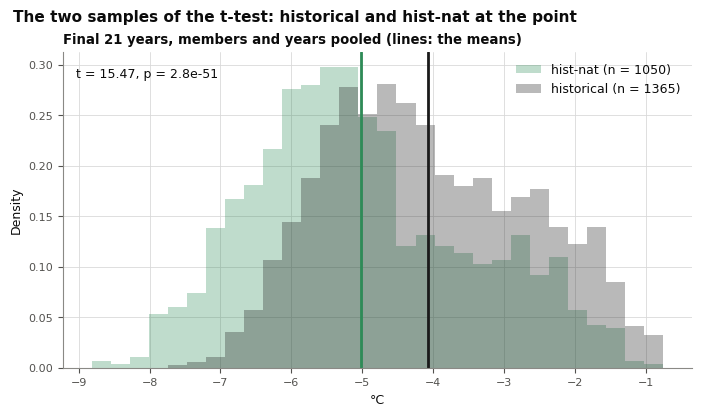

In [165]:
#(t): The two samples the t-test compares: the final WINDOW years of each ensemble, members and years pooled, with
#(t): their means
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=1, n_legends=0, panel_width=6.0, panel_height=2.8),
                 layout='constrained')
axes = fig.add_gridspec(1, 1).subplots(squeeze=False)
methods.plot_two_samples(demo_experiment_final_da, demo_histnat_final_da, DEMO_EXPERIMENT, t=float(demo_t_ds.t),
                         p=float(demo_t_ds.p), ax=axes[0, 0])
axes[0, 0].set_title(f'Final {WINDOW} years, members and years pooled (lines: the means)', loc='left')
axes[0, 0].set_xlabel(VARIABLE.units)
axes[0, 0].set_ylabel('Density')
fig.suptitle(f'The two samples of the t-test: {DEMO_EXPERIMENT} and hist-nat at the point', x=0.01, ha='left');

In [166]:
#(t): Every experiment's model's hist-nat over the same final years, in a tree shaped like lesfmip_final_tree
hist_nat_final_tree = datatree.hist_nat_like(lesfmip_final_tree)

In [167]:
#(t): The Welch t-test, mapped over every experiment and its model's hist-nat
ttest_tree = xr.map_over_datasets(partial(sig.ttest_welch, variable=VARIABLE.name), lesfmip_final_tree,
                                  hist_nat_final_tree)

In [168]:
%%time
#(t): No member dim left, so one Dataset (hist-nat against itself is t = 0)
ttest_ds = datatree.tree_to_dataset(ttest_tree, dims=['model', 'experiment']).compute()
ttest_ds

CPU times: user 72.3 ms, sys: 12.4 ms, total: 84.7 ms
Wall time: 1.67 s


<xarray.Dataset> Size: 6MB
Dimensions:     (model: 6, experiment: 5, lon: 144, season: 4, lat: 20)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Data variables:
    t           (lat, lon, season, model, experiment) float64 3MB 61.06 ... 1...
    p           (lat, lon, season, model, experiment) float64 3MB 0.0 ... 2.3...

In [169]:
#(t): Saved for notebooks plot_03 to plot_06
ttest_path = RESULTS_DIR / 'ttest.zarr'
ttest_ds.to_zarr(ttest_path, mode='w')
ttest_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/ttest.zarr')

In [170]:
#(t): Its value at the demonstration point: the same t as above
ttest_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 112B
Dimensions:     ()
Coordinates:
    model       <U7 28B 'CanESM5'
    experiment  <U10 40B 'historical'
    lon         float64 8B -180.0
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
Data variables:
    t           float64 8B 15.47
    p           float64 8B 2.776e-51

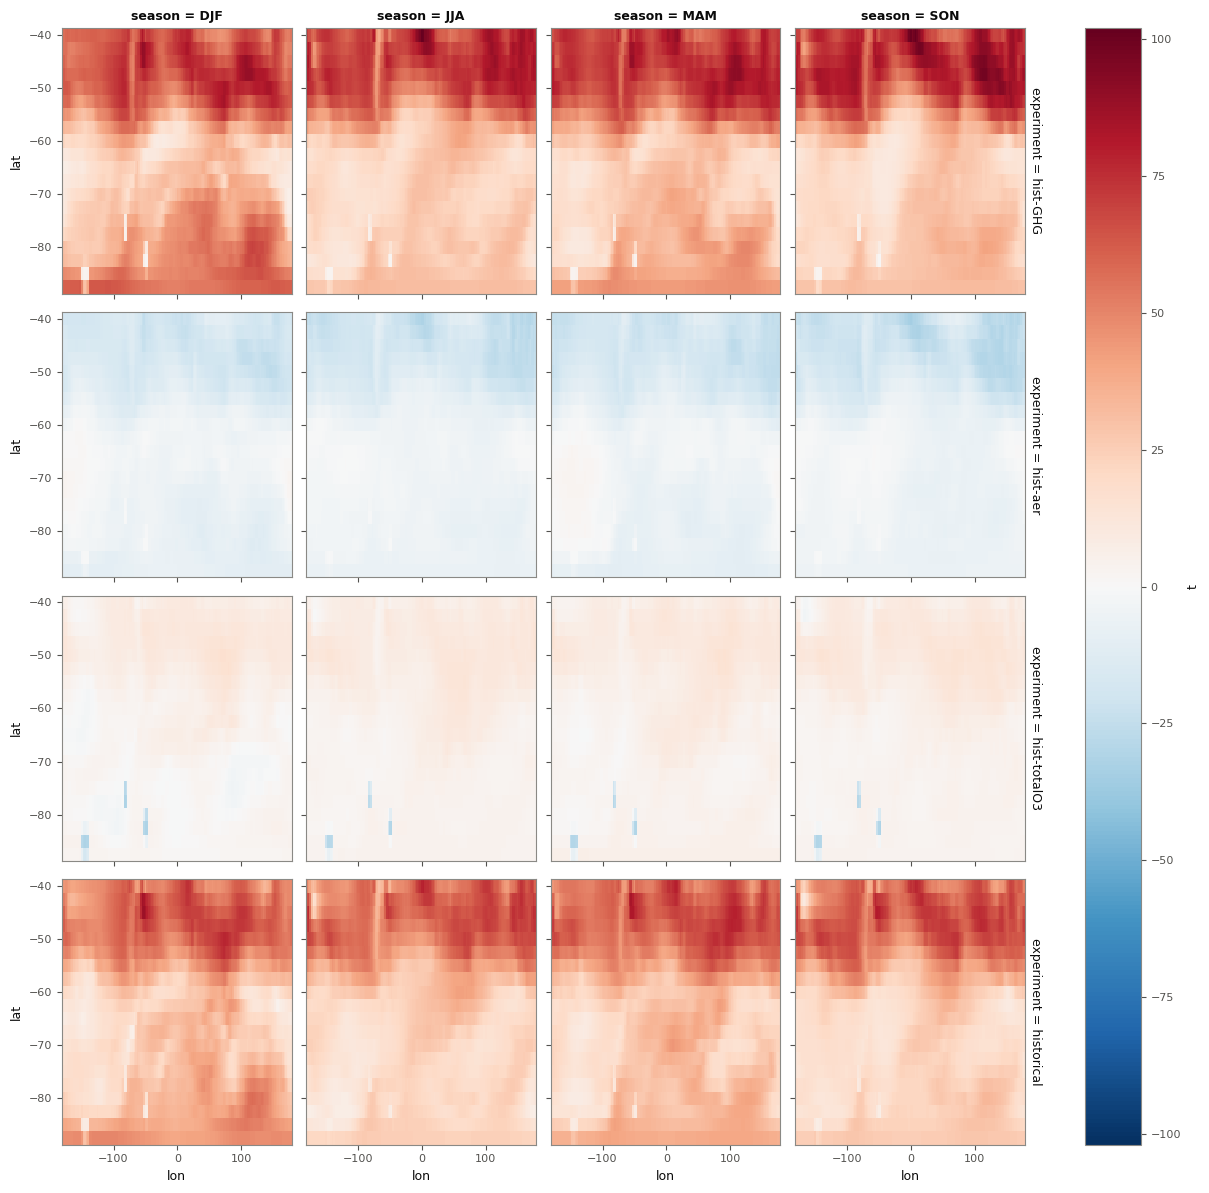

In [171]:
#(t): Quick look: t for DEMO_MODEL, experiments down and seasons across, on the plain lat-lon grid
ttest_ds['t'].sel(model=DEMO_MODEL, experiment=config.FORCED_EXPERIMENTS).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

### Welch t-test on the rolling medians

The same test on notebook calc_02a's rolling medians (its section 1) $Q_{50}(t)$, each of which pools every member's values in the $L$ years centred on $t$. It takes the last $L$ years that have a complete window (centres 1983–2003, whose windows cover 1973–2013): $L$ values for the experiment and $L$ for hist-nat, and $\nu$ comes from those. Neighbouring medians share $L - 1$ of their $L$ years, so the values are far from independent and the test is overconfident: it is here to see by how much.

In [172]:
#(t): The last WINDOW years with a complete window: up to LAST_FULL_YEAR, the centre of the final WINDOW years
ROLLING_FINAL_YEARS = slice(config.LAST_FULL_YEAR - WINDOW + 1, config.LAST_FULL_YEAR + 1)

In [ ]:
#(t): The rolling quantiles notebook calc_02a saved (its section 1), on (model, experiment, quantile, year, season,
#(t): lat, lon)
rolling_quantiles_path = RESULTS_DIR / 'rolling_quantiles.zarr'
rolling_quantiles_path

In [ ]:
rolling_quantiles_ds = xr.open_zarr(rolling_quantiles_path)

In [ ]:
#(t): The demonstration point picked out of them, on (experiment, quantile, year)
point_rolling_da = rolling_quantiles_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON).load()
point_rolling_da

In [ ]:
#(t): The rolling medians at the demonstration point, every experiment, on (experiment, year): from point_rolling_da
#(t): (above)
demo_rolling_median_da = point_rolling_da.sel(quantile=0.5, drop=True)

In [174]:
#(t): Over those years
demo_rolling_median_final_da = demo_rolling_median_da.isel(year=ROLLING_FINAL_YEARS)

In [175]:
#(t): DEMO_EXPERIMENT's, and hist-nat's
demo_experiment_rolling_median_da = demo_rolling_median_final_da.sel(experiment=DEMO_EXPERIMENT)
demo_histnat_rolling_median_da = demo_rolling_median_final_da.sel(experiment='hist-nat')

In [176]:
#(t): The Welch t-test of the two, over the years alone
demo_t_rolling_median_ds = sig.ttest_welch(demo_experiment_rolling_median_da, demo_histnat_rolling_median_da,
                                           dims=('year',))
demo_t_rolling_median_ds

<xarray.Dataset> Size: 72B
Dimensions:  ()
Coordinates:
    model    <U7 28B 'CanESM5'
    lon      float64 8B -180.0
    season   <U3 12B 'DJF'
    lat      float64 8B -75.0
Data variables:
    t        float64 8B 45.58
    p        float64 8B 6.504e-29

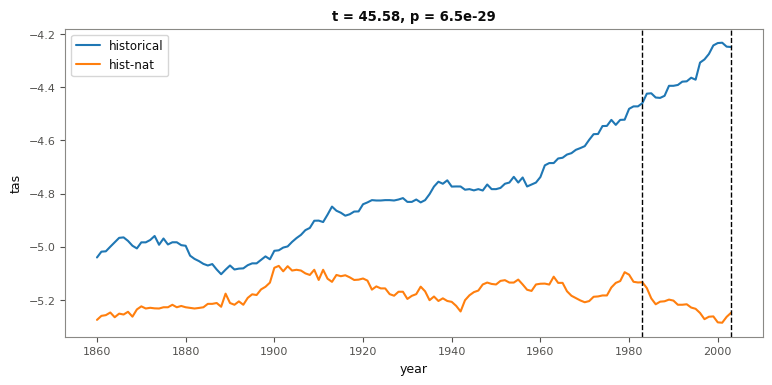

In [177]:
#(t): Quick look: the two rolling medians through time; the years tested are between the dashed lines
fig, ax = plt.subplots(figsize=(9, 4))
demo_rolling_median_da.sel(experiment=DEMO_EXPERIMENT).plot(ax=ax, label=DEMO_EXPERIMENT)
demo_rolling_median_da.sel(experiment='hist-nat').plot(ax=ax, label='hist-nat')
ax.axvline(int(demo_rolling_median_final_da.year[0]), color='k', ls='--', lw=1)
ax.axvline(int(demo_rolling_median_final_da.year[-1]), color='k', ls='--', lw=1)
ax.set_title(f"t = {float(demo_t_rolling_median_ds['t']):.2f}, p = {float(demo_t_rolling_median_ds['p']):.3g}")
ax.legend();

Now everywhere, from `rolling_quantiles_ds` (above).

In [ ]:
#(t): The rolling medians of every model and experiment (notebook calc_02a, section 1)
rolling_median_da = rolling_quantiles_ds[VARIABLE.name].sel(quantile=0.5, drop=True)

In [179]:
#(t): Over the last WINDOW years with a complete window
rolling_median_final_da = rolling_median_da.isel(year=ROLLING_FINAL_YEARS)

In [180]:
#(t): hist-nat's, and every other experiment's
hist_nat_rolling_median_da = rolling_median_final_da.sel(experiment='hist-nat', drop=True)
experiment_rolling_median_da = rolling_median_final_da.drop_sel(experiment='hist-nat')

In [181]:
%%time
#(t): The Welch t-test over the years alone, every experiment against its model's hist-nat
ttest_rolling_median_ds = sig.ttest_welch(experiment_rolling_median_da, hist_nat_rolling_median_da,
                                          dims=('year',)).compute()
ttest_rolling_median_ds

CPU times: user 264 ms, sys: 9.97 ms, total: 274 ms
Wall time: 275 ms


<xarray.Dataset> Size: 4MB
Dimensions:     (model: 6, experiment: 4, lon: 144, season: 4, lat: 20)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Data variables:
    t           (lat, lon, season, model, experiment) float64 2MB 33.32 ... 7...
    p           (lat, lon, season, model, experiment) float64 2MB 4.229e-19 ....

In [182]:
#(t): Saved for notebooks plot_03 to plot_06
ttest_rolling_median_path = RESULTS_DIR / 'ttest_rolling_median.zarr'
ttest_rolling_median_ds.to_zarr(ttest_rolling_median_path, mode='w')
ttest_rolling_median_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/ttest_rolling_median.zarr')

In [183]:
#(t): Its value at the demonstration point: the same t as above
ttest_rolling_median_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 112B
Dimensions:     ()
Coordinates:
    model       <U7 28B 'CanESM5'
    experiment  <U10 40B 'historical'
    lon         float64 8B -180.0
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0
Data variables:
    t           float64 8B 45.58
    p           float64 8B 6.504e-29

### Member-block permutation test

The Welch t-test above pools `WINDOW` years × N members as if every value were independent. But a member's years are serially correlated, so the pooled test is overconfident: in synthetic data with a lag-1 autocorrelation of 0.6, it rejects a true null 29% of the time at p < 0.05, against 5% for this test. (Antarctic seasonal means are usually less correlated than that, so the effect here is smaller, but it is there.)

Members, however, are independent realisations. So this test permutes **whole members** between the experiment and hist-nat, keeping each member's years together as a block. Because every member covers the same years, permuting whole members is the same as permuting member means, so the test runs as one matrix product per batch of permutations.

The test statistic is the difference in means, $\Delta = \bar{x}_{\mathrm{exp}} - \bar{x}_{\mathrm{nat}}$. Each permutation relabels $M_{\mathrm{exp}}$ of the pooled members as the experiment and the other $M_{\mathrm{nat}}$ as hist-nat, keeping each member's years together, and computes the same $\Delta$; the p-value counts the permutations at least as extreme, as for the bootstrap. Step by step, at the demonstration point:

In [184]:
#(t): Each member's mean over the final WINDOW years at the point: the experiment's
demo_experiment_member_mean_da = demo_experiment_final_da.mean('year')

In [185]:
#(t): and hist-nat's
demo_histnat_member_mean_da = demo_histnat_final_da.mean('year')

In [186]:
#(t): The observed difference in means
demo_mean_change_da = demo_experiment_member_mean_da.mean('member') - demo_histnat_member_mean_da.mean('member')

In [187]:
#(t): The relabellings: each row has +1/M_exp on the members it calls the experiment and -1/M_nat on the rest
#(c): The same draws as the full test below: rc.member_block_pvalue draws from default_rng(0) too
demo_n_exp = demo_experiment_member_mean_da.sizes['member']
demo_n_nat = demo_histnat_member_mean_da.sizes['member']
demo_weights_arr = rc.permutation_weights(N_PERMUTATIONS, demo_n_exp, demo_n_nat, np.random.default_rng(0))
demo_weights_arr.shape

(5000, 115)

In [188]:
#(t): The pooled member means, the experiment's first
demo_pooled_arr = np.concatenate([demo_experiment_member_mean_da.values, demo_histnat_member_mean_da.values])

In [189]:
#(t): Each relabelling's difference in means: the null
demo_permutations_da = xr.DataArray(demo_weights_arr @ demo_pooled_arr, dims='trial')

In [190]:
#(t): How rc.permutation_weights relabels the members: one random number for every pooled member, and the M_exp smallest
#(t): are called the experiment
# Example: 3 experiment members and 2 hist-nat members, pooled as [e0, e1, e2, n0, n1]. The random numbers
# [0.6, 0.2, 0.9, 0.1, 0.4] put them in the order [3, 1, 4, 0, 2] (np.argsort), so pooled members 3, 1 and 4 are called
# the experiment, with a weight of +1/3 each, and 0 and 2 hist-nat, with -1/2 each: the row [-1/2, 1/3, -1/2, 1/3, 1/3].
# The row times the member means, added up, is the mean of 3, 1 and 4 minus the mean of 0 and 2: that relabelling's difference.
# Check on the first relabelling: its weights times the member means, and the two means taken directly
demo_relabelled_arr = demo_weights_arr[0] > 0
(float(demo_weights_arr[0] @ demo_pooled_arr),
 float(demo_pooled_arr[demo_relabelled_arr].mean() - demo_pooled_arr[~demo_relabelled_arr].mean()))

(0.20139223685631386, 0.20139265060424805)

In [191]:
#(t): The p-value: where the observed difference falls among the relabellings'
demo_mean_pvalue_da = sig.pvalue_two_sided(demo_permutations_da, demo_mean_change_da)
demo_mean_pvalue_da

<xarray.DataArray ()> Size: 8B
0.0003999
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

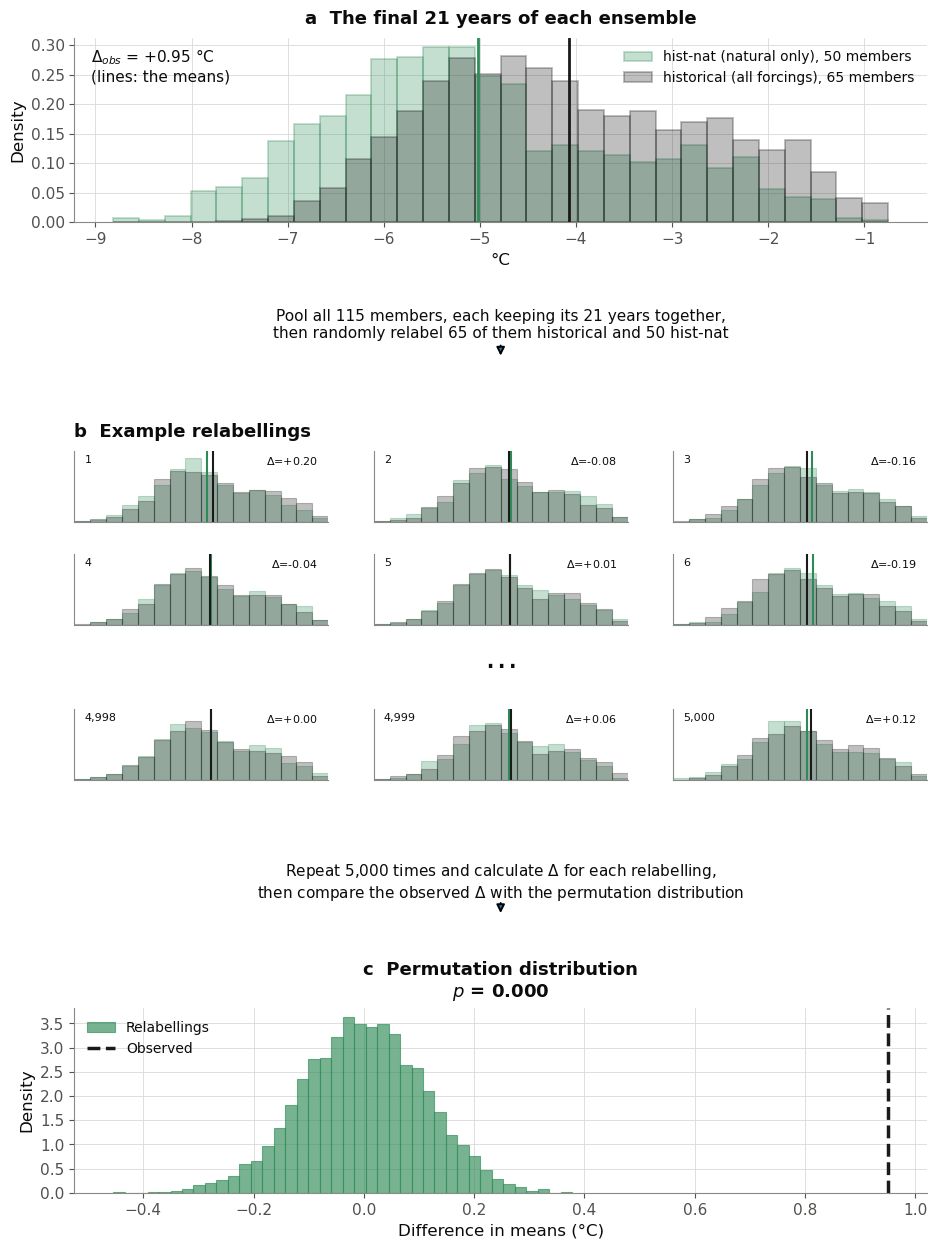

In [192]:
#(t): The member-block permutation test of the mean change, step by step: a) the two ensembles' final years and their
#(t): means; b) example relabellings, whole members shuffled between the labels; c) every relabelling's difference in
#(t): means, and the observed one. The relabellings in b are rebuilt and checked against demo_permutations_da
n_experiment_members = demo_experiment_final_da.sizes['member']
n_histnat_members = demo_histnat_final_da.sizes['member']
n_final_years = demo_experiment_final_da.sizes['year']
n_permutations = demo_permutations_da.sizes['trial']
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 15))
    ax_a, flow_axes, trial_axes, ax_c = methods.schematic_axes(fig)

    methods.plot_two_ensembles(demo_histnat_final_da, demo_experiment_final_da, DEMO_EXPERIMENT, units=VARIABLE.units,
                               ax=ax_a)
    ax_a.set_title(f'a  The final {n_final_years} years of each ensemble', pad=10)
    ax_a.set_xlabel(VARIABLE.units)
    ax_a.set_ylabel('Density')

    methods.plot_flow(f'Pool all {n_experiment_members + n_histnat_members} members, each keeping its {n_final_years} '
                      f'years together,\nthen randomly relabel {n_experiment_members} of them {DEMO_EXPERIMENT} and '
                      f'{n_histnat_members} hist-nat', flow_axes[0])
    methods.plot_relabellings(demo_experiment_final_da, demo_histnat_final_da, demo_weights_arr > 0, demo_permutations_da,
                              DEMO_EXPERIMENT, trial_axes)
    trial_axes[0, 0].set_title('b  Example relabellings', loc='left', pad=10)
    methods.plot_flow(f'Repeat {n_permutations:,} times and calculate $\\Delta$ for each relabelling,\n'
                      'then compare the observed $\\Delta$ with the permutation distribution', flow_axes[1])

    methods.plot_permutation_distribution(demo_permutations_da, demo_mean_change_da, DEMO_EXPERIMENT, ax=ax_c)
    ax_c.set_title(f'c  Permutation distribution\n$p$ = {float(demo_mean_pvalue_da):.3f}', pad=8)
    ax_c.set_xlabel(f'Difference in means ({VARIABLE.units})')
    ax_c.set_ylabel('Density');

In [193]:
#(t): Each member's mean over the final WINDOW years, everywhere
member_mean_tree = lesfmip_final_tree.mean('year')

In [194]:
#(t): Its model's hist-nat member means alongside every experiment
hist_nat_member_mean_tree = datatree.hist_nat_like(member_mean_tree)

In [195]:
#(t): The member-block test, mapped over every experiment and its model's hist-nat
mean_block_pvalue_tree = xr.map_over_datasets(partial(rc.member_block_pvalue, n_permutations=N_PERMUTATIONS),
                                              member_mean_tree, hist_nat_member_mean_tree)

In [196]:
%%time
#(t): Its p-values in one Dataset (hist-nat against itself left out)
mean_block_pvalue_ds = datatree.tree_to_dataset(mean_block_pvalue_tree, dims=['model', 'experiment']).compute()
mean_block_pvalue_da = mean_block_pvalue_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

CPU times: user 47.8 ms, sys: 4.75 ms, total: 52.6 ms
Wall time: 2.23 s


In [197]:
%%time
#(t): Every experiment's ensemble mean over its final years
final_mean_tree = member_mean_tree.mean('member')
final_mean_ds = datatree.tree_to_dataset(final_mean_tree, dims=['model', 'experiment']).compute()
final_mean_ds

CPU times: user 83.9 ms, sys: 8.41 ms, total: 92.3 ms
Wall time: 694 ms


<xarray.Dataset> Size: 1MB
Dimensions:     (model: 6, experiment: 5, lon: 144, season: 4, lat: 20)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Data variables:
    tas         (lat, lon, season, model, experiment) float32 1MB -24.78 ... ...

In [198]:
#(t): The mean response: each experiment minus hist-nat over the same final years, members pooled
mean_response_ds = final_mean_ds - final_mean_ds.sel(experiment='hist-nat')
mean_response_ds = mean_response_ds.drop_sel(experiment='hist-nat')
mean_response_da = mean_response_ds[VARIABLE.name].rename('mean_response')

In [199]:
#(t): The member-block test in one Dataset, laid out as notebook plot_03 opens it
mean_block_ds = xr.Dataset({'mean_change': mean_response_da, 'pvalue': mean_block_pvalue_da})
mean_block_ds

<xarray.Dataset> Size: 3MB
Dimensions:      (model: 6, experiment: 4, lon: 144, season: 4, lat: 20)
Coordinates:
  * model        (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment   (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon          (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * season       (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat          (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
Data variables:
    mean_change  (lat, lon, season, model, experiment) float32 1MB 2.339 ... ...
    pvalue       (lat, lon, season, model, experiment) float64 2MB 0.0003999 ...

In [200]:
#(t): Saved for notebooks plot_03 to plot_06
final_mean_path = RESULTS_DIR / 'final_mean.zarr'
final_mean_ds.to_zarr(final_mean_path, mode='w')
final_mean_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/final_mean.zarr')

In [201]:
#(t): Saved for notebooks plot_03 to plot_06
mean_block_path = RESULTS_DIR / 'mean_block.zarr'
mean_block_ds.to_zarr(mean_block_path, mode='w')
mean_block_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/mean_block.zarr')

In [ ]:
#(t): The mean response, saved for notebooks plot_03 to plot_06, which draw it next to notebook calc_02a's
#(t): change in width and tails
mean_response_path = RESULTS_DIR / 'mean_response.zarr'
mean_response_da.to_dataset(name='mean_response').to_zarr(mean_response_path, mode='w')
mean_response_path

In [202]:
#(t): Its value at the demonstration point: the same change and p-value as the step-by-step test above
mean_block_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 108B
Dimensions:      ()
Coordinates:
    model        <U7 28B 'CanESM5'
    experiment   <U10 40B 'historical'
    lon          float64 8B -180.0
    season       <U3 12B 'DJF'
    lat          float64 8B -75.0
Data variables:
    mean_change  float32 4B 0.9505
    pvalue       float64 8B 0.0003999

### hist-nat bootstrap of the mean (the figures' test)

The width test of notebook calc_02a (section 2), with the mean in place of the width. **The change** is each experiment's mean over the final $L$ years minus hist-nat's over the same years, members and years pooled, the same change as the member-block test's:

$$
\Delta\bar{x} = \bar{x}^{\,\mathrm{exp}}_{\text{final } L \text{ years}} - \bar{x}^{\,\mathrm{nat}}_{\text{final } L \text{ years}}.
$$

**Its null** comes from the trials of notebook calc_02a's section 2, the very same draws: trial $k$ pools the values of 10 different hist-nat members over the final $L$ years and takes their mean,

$$
\bar{x}_k = \frac{1}{nL} \sum_{m \in S_k} \sum_{y} x^{\mathrm{nat}}_{m,y}, \qquad k = 1, \ldots, N,
$$

and the p-value counts the trials at least as far out as the experiment's mean $\bar{x}^{\,\mathrm{exp}}$, on either side, as for the width. The trials are whole members, so the correlation between a member's years, which makes the pooled Welch test overconfident, is in them too. How well the test holds for each ensemble size is in notebook calc_02a, section 2.

Step by step at the demonstration point, with the draws of calc_02a's section 2 (`demo_selected_arr`, made again here):

In [ ]:
#(t): The bootstrap's draws: each trial's hist-nat members, (trial, member), the same as notebook calc_02a's
#(t): width test (the same seed)
demo_selected_arr = sig.bootstrap_draws(demo_histnat_final_da.sizes['member'], n_trials=DEMO_TRIALS, seed=0)
demo_selected_arr.shape

In [90]:
#(t): How sig.bootstrap_draws picks each trial's members: one random number for every member, and the 10 smallest are drawn
# Example: 5 members and 2 per trial. The random numbers [0.7, 0.1, 0.5, 0.9, 0.3] are smallest at members 1 and 4, so the
# trial draws members 1 and 4, and its row of demo_selected_arr is [False, True, False, False, True].
# Every set of 2 members is as likely as any other, and no member is drawn twice in a trial. Here the members of trial 0:
demo_trial_0_members_arr = np.flatnonzero(demo_selected_arr[0])
demo_trial_0_members_arr

array([ 2,  3, 11, 13, 15, 20, 21, 32, 46, 48])

In [203]:
#(t): hist-nat's mean over the final WINDOW years at the point, members and years pooled
demo_hist_nat_mean_da = demo_histnat_final_da.mean(['member', 'year'])

In [204]:
#(t): The experiment's over the same years
demo_experiment_mean_da = demo_experiment_final_da.mean(['member', 'year'])

In [205]:
#(t): The change being tested
demo_bootstrap_change_da = demo_experiment_mean_da - demo_hist_nat_mean_da
demo_bootstrap_change_da

<xarray.DataArray 'tas' ()> Size: 4B
0.9505
Coordinates:
    lon      float64 8B -180.0
    lat      float64 8B -75.0
    season   <U3 12B 'DJF'

In [206]:
%%time
#(t): Each trial's mean, from the same draws as the width test (the same seed), on (trial)
demo_trial_mean_da = sig.bootstrap_mean(demo_histnat_final_da, n_trials=DEMO_TRIALS, seed=0)

CPU times: user 1.34 s, sys: 0 ns, total: 1.34 s
Wall time: 66.6 ms


In [207]:
#(t): How sig.bootstrap_mean gets every trial's mean at once: each member's sum over the years, and how many values it has
# A trial's mean is the sum of its members' values over how many values there are.
# Example: a trial of 2 members whose 21 values add up to 10 and to 14: its mean is (10 + 14) / (21 + 21) = 0.57.
demo_member_sum_da = demo_histnat_final_da.sum('year')
demo_member_count_da = demo_histnat_final_da.count('year')

In [208]:
#(t): ... added up for every trial at once, as a matrix product with the draws (stats.weighted_member_sums)
# Each row of demo_selected_arr is 1 on the trial's members and 0 on the rest (True and False as numbers).
# Example: the row [0, 1, 0, 0, 1] times the sums [8, 10, 9, 12, 14], added up, is 10 + 14 = 24: the trial's total.
# The matrix product does that for every row, so for every trial, in one step.
demo_trial_total_arr = demo_selected_arr.astype(float) @ demo_member_sum_da.values
demo_trial_count_arr = demo_selected_arr.astype(float) @ demo_member_count_da.values

In [209]:
#(t): Check: trial 0's mean three ways: its members' values gathered and averaged, the sums above, and sig.bootstrap_mean
(float(demo_histnat_final_da.isel(member=demo_trial_0_members_arr).mean()),
 float(demo_trial_total_arr[0] / demo_trial_count_arr[0]), float(demo_trial_mean_da.isel(trial=0)))

(-5.073878765106201, -5.073878551664807, -5.073878589698246)

In [210]:
#(t): The p-value: where the experiment's mean falls among the trials'
demo_bootstrap_pvalue_da = sig.pvalue_two_sided(demo_trial_mean_da, demo_experiment_mean_da)
demo_bootstrap_pvalue_da

<xarray.DataArray 'tas' ()> Size: 8B
0.0002
Coordinates:
    lat      float64 8B -75.0
    lon      float64 8B -180.0
    season   <U3 12B 'DJF'

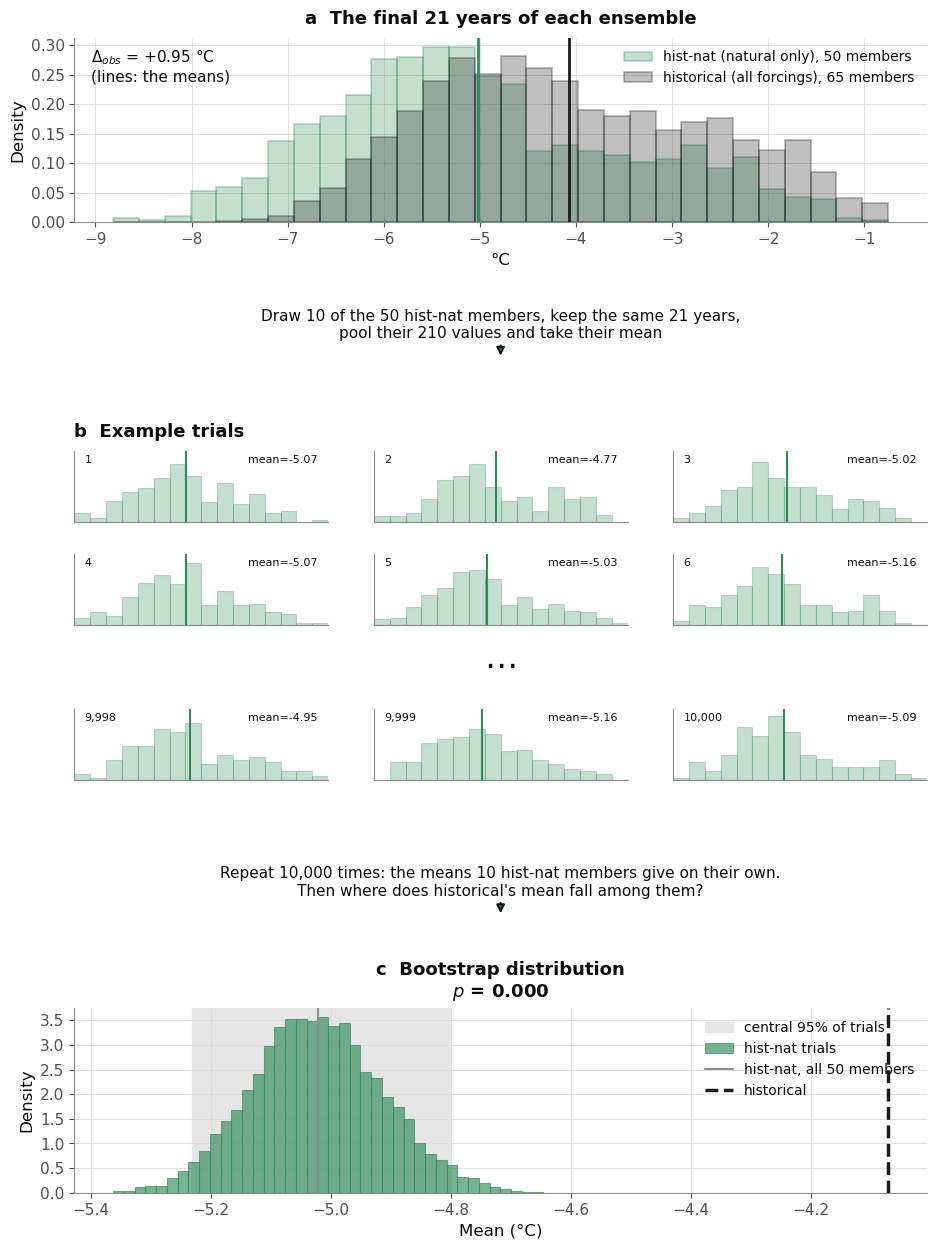

In [211]:
#(t): The hist-nat bootstrap of the mean, step by step, on the width test's draws: a) the two ensembles over the same
#(t): final years, with their means; b) example trials, each N hist-nat members over those years; c) every trial's
#(t): mean, and the experiment's. The trials in b are rebuilt from demo_selected_arr and checked against
#(t): demo_trial_mean_da
n_histnat_members = demo_histnat_final_da.sizes['member']
n_drawn = int(demo_selected_arr[0].sum())
n_final_years = demo_histnat_final_da.sizes['year']
n_trials = demo_trial_mean_da.sizes['trial']
#(c): In the slides' big text, as the schematics are shown in talks too
with plt.rc_context(fr.SLIDES.rc):
    fig = plt.figure(figsize=(11, 15))
    ax_a, flow_axes, trial_axes, ax_c = methods.schematic_axes(fig)

    methods.plot_two_ensembles(demo_histnat_final_da, demo_experiment_final_da, DEMO_EXPERIMENT, units=VARIABLE.units,
                               ax=ax_a)
    ax_a.set_title(f'a  The final {n_final_years} years of each ensemble', pad=10)
    ax_a.set_xlabel(VARIABLE.units)
    ax_a.set_ylabel('Density')

    methods.plot_flow(f'Draw {n_drawn} of the {n_histnat_members} hist-nat members, keep the same {n_final_years} years,\n'
                      f'pool their {n_drawn * n_final_years} values and take their mean', flow_axes[0])
    methods.plot_mean_trials(demo_histnat_final_da, demo_selected_arr, demo_trial_mean_da, trial_axes)
    trial_axes[0, 0].set_title('b  Example trials', loc='left', pad=10)
    methods.plot_flow(f'Repeat {n_trials:,} times: the means {n_drawn} hist-nat members give on their own.\n'
                      f"Then where does {DEMO_EXPERIMENT}'s mean fall among them?", flow_axes[1])

    methods.plot_trial_distribution(demo_trial_mean_da, demo_experiment_mean_da, demo_hist_nat_mean_da, DEMO_EXPERIMENT,
                                    n_histnat_members, ax=ax_c)
    ax_c.set_title(f'c  Bootstrap distribution\n$p$ = {float(demo_bootstrap_pvalue_da):.3f}', pad=8)
    ax_c.set_xlabel(f'Mean ({VARIABLE.units})')
    ax_c.set_ylabel('Density');

Now at every grid point. As for the width, the trials come from hist-nat alone, so they are drawn once per model (one function mapped over the hist-nat nodes), and every experiment of that model is tested against the same trials.

In [212]:
#(t): hist-nat's mean over the final WINDOW years, from final_mean_ds (above)
hist_nat_mean_da = final_mean_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)

In [213]:
#(t): every other experiment's
experiment_mean_da = final_mean_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

In [214]:
#(t): The change being tested (the same numbers as mean_response_da)
mean_bootstrap_change_da = experiment_mean_da - hist_nat_mean_da

In [ ]:
%%time
#(t): Each trial's mean, from hist-nat's final WINDOW years alone: the draws of the width test (notebook calc_02a,
#(t): section 2), the same seed
trial_mean_ds = datatree.reduce_to_dataset(
    lesfmip_final_tree.match('*/hist-nat'), partial(sig.bootstrap_mean, n_trials=N_TRIALS, seed=0),
)
trial_mean_da = trial_mean_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True).persist()
wait(trial_mean_da)

In [216]:
%%time
#(t): The two-sided p-value of every experiment's mean against its model's trials
mean_bootstrap_pvalue_da = sig.pvalue_two_sided(trial_mean_da, experiment_mean_da).compute()

CPU times: user 28.4 ms, sys: 2.23 ms, total: 30.6 ms
Wall time: 746 ms


In [ ]:
#(t): The trials as changes: each trial's mean minus hist-nat's (for the bounds, and the zonal test of section 4)
null_mean_da = trial_mean_da - hist_nat_mean_da

In [218]:
%%time
#(t): Their central 1 - ALPHA: a change outside it is significant
null_mean_bounds_da = nan_quantile(null_mean_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 8.73 ms, sys: 2.88 ms, total: 11.6 ms
Wall time: 386 ms


In [219]:
#(t): The hist-nat bootstrap of the mean in one Dataset, laid out as notebooks plot_03 to plot_06 open it (mean_change and pvalue
#(t): as in mean_block)
mean_bootstrap_ds = xr.Dataset({
    'hist_nat_mean': hist_nat_mean_da,
    'experiment_mean': experiment_mean_da,
    'mean_change': mean_bootstrap_change_da,
    'null_lower': null_mean_bounds_da.isel(quantile=0, drop=True),
    'null_upper': null_mean_bounds_da.isel(quantile=1, drop=True),
    'pvalue': mean_bootstrap_pvalue_da,
})
mean_bootstrap_ds

<xarray.Dataset> Size: 6MB
Dimensions:          (model: 6, lon: 144, season: 4, lat: 20, experiment: 4)
Coordinates:
  * model            (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon              (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * season           (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat              (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * experiment       (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    hist_nat_mean    (lat, lon, season, model) float32 276kB -27.12 ... 13.83
    experiment_mean  (lat, lon, season, model, experiment) float32 1MB -24.78...
    mean_change      (lat, lon, season, model, experiment) float32 1MB 2.339 ...
    null_lower       (lat, lon, season, model) float64 553kB -0.142 ... -0.06187
    null_upper       (lat, lon, season, model) float64 553kB 0.1417 ... 0.06617
    pvalue           (lat, lon, season, model, experiment) float64 2MB 0.0019...

In [220]:
#(t): Saved for notebooks plot_03 to plot_06
mean_bootstrap_path = RESULTS_DIR / 'mean_bootstrap.zarr'
mean_bootstrap_ds.to_zarr(mean_bootstrap_path, mode='w')
mean_bootstrap_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/mean_bootstrap.zarr')

In [221]:
#(t): Its value at the demonstration point: the same change and mean as step by step above (the p-value comes from
#(t): N_TRIALS trials there, DEMO_TRIALS here, so it differs a little)
mean_bootstrap_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON)

<xarray.Dataset> Size: 132B
Dimensions:          ()
Coordinates:
    model            <U7 28B 'CanESM5'
    lon              float64 8B -180.0
    season           <U3 12B 'DJF'
    lat              float64 8B -75.0
    experiment       <U10 40B 'historical'
Data variables:
    hist_nat_mean    float32 4B -5.021
    experiment_mean  float32 4B -4.071
    mean_change      float32 4B 0.9505
    null_lower       float64 8B -0.2079
    null_upper       float64 8B 0.2088
    pvalue           float64 8B 0.001998

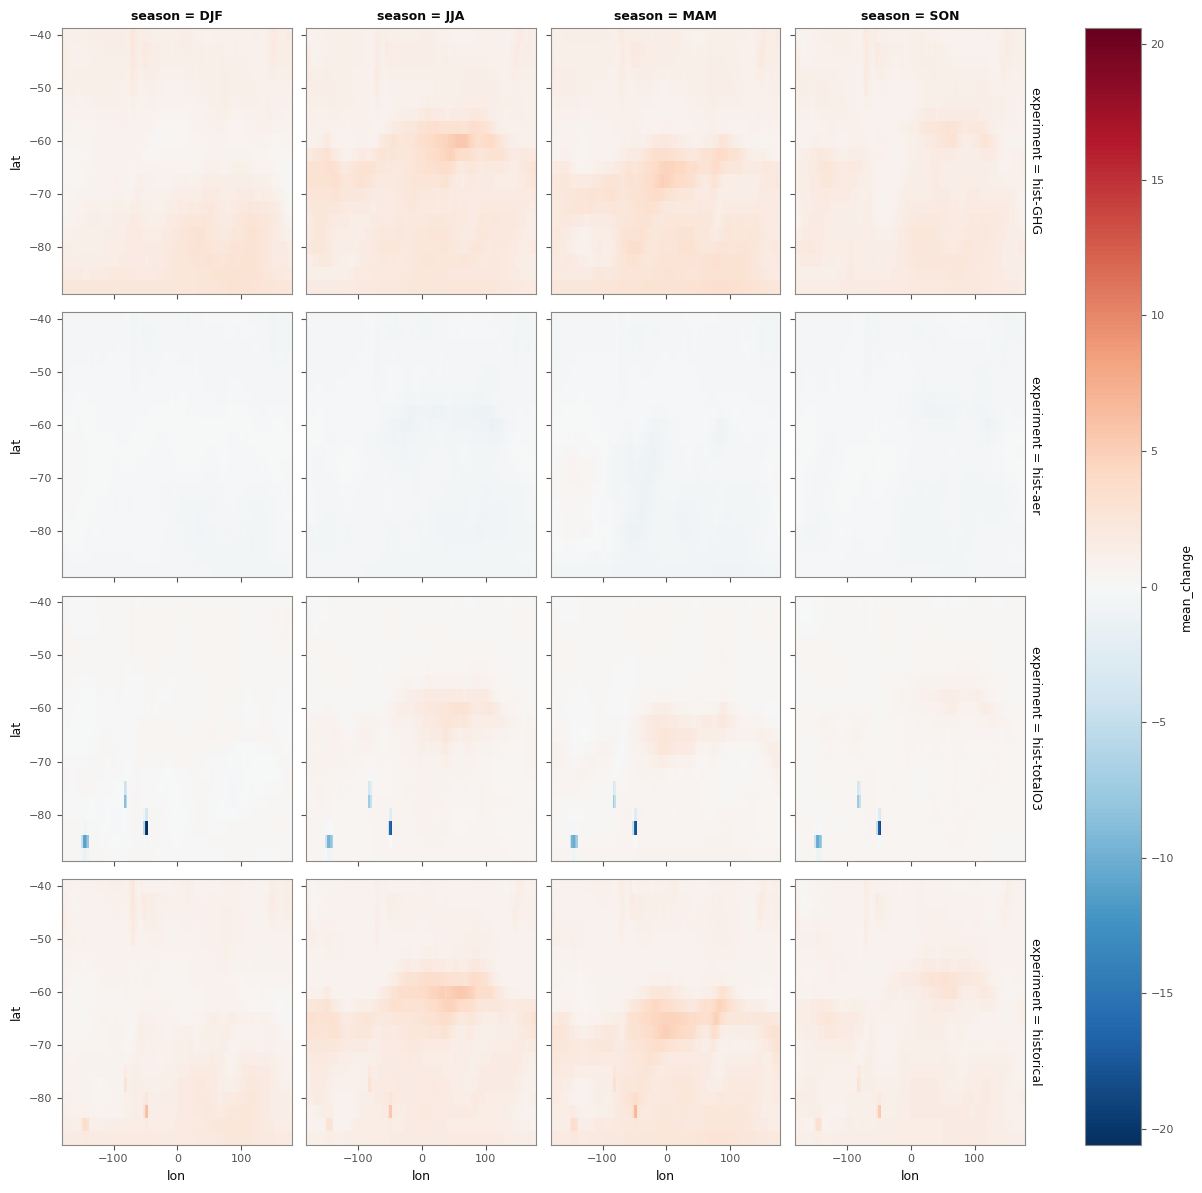

In [222]:
#(t): Quick look: the change in the mean for DEMO_MODEL, experiments down and seasons across, on the plain lat-lon grid
mean_bootstrap_ds['mean_change'].sel(model=DEMO_MODEL).plot(
    x='lon', y='lat', row='experiment', col='season', cmap='RdBu_r', center=0);

### Four tests side by side

The share of the area each test calls significant ($p < 0.05$), averaged over models and seasons. The two Welch tests count correlated values as independent, so they call too much; the member-block test and the hist-nat bootstrap both compare with hist-nat's final $L$ years.

In [223]:
#(t): Where each test calls the change significant (p < ALPHA), NaN where there is no data
ttest_significant_da = (ttest_ds['p'] < ALPHA).where(ttest_ds['p'].notnull())
ttest_rolling_median_significant_da = (ttest_rolling_median_ds['p'] < ALPHA).where(
    ttest_rolling_median_ds['p'].notnull())
mean_block_significant_da = (mean_block_ds['pvalue'] < ALPHA).where(mean_block_ds['pvalue'].notnull())
mean_bootstrap_significant_da = (mean_bootstrap_ds['pvalue'] < ALPHA).where(mean_bootstrap_ds['pvalue'].notnull())

In [224]:
#(t): % of the area each test calls significant, averaged over models and seasons
ttest_area_da = 100 * sig.area_mean(ttest_significant_da.sel(experiment=config.FORCED_EXPERIMENTS)).mean(['model', 'season'])
ttest_rolling_median_area_da = 100 * sig.area_mean(ttest_rolling_median_significant_da).mean(['model', 'season'])
mean_block_area_da = 100 * sig.area_mean(mean_block_significant_da).mean(['model', 'season'])
mean_bootstrap_area_da = 100 * sig.area_mean(mean_bootstrap_significant_da).mean(['model', 'season'])
pd.DataFrame({'Welch t-test (years pooled)': ttest_area_da.to_series(),
              'Welch t-test (rolling medians)': ttest_rolling_median_area_da.to_series(),
              'member-block test': mean_block_area_da.to_series(),
              'hist-nat bootstrap': mean_bootstrap_area_da.to_series()}).round(0)

,Welch t-test (years pooled),Welch t-test (rolling medians),member-block test,hist-nat bootstrap
experiment,,,,
hist-GHG,97.0,99.0,96.0,95.0
hist-aer,72.0,93.0,62.0,67.0
hist-totalO3,74.0,92.0,64.0,66.0
historical,96.0,99.0,95.0,94.0


### By SAM phase

The hist-nat bootstrap of the mean in the seasons of each SAM phase alone (*SAM Phases*, above): each experiment's mean in a phase against hist-nat's in the same phase, and against the same trials, each pooling only its members' seasons in that phase (about 70 of its 210). The change in a phase is how much a forcing has changed the seasons with that state of the SAM. So it leaves out most of the change that comes from the SAM spending more time in one phase; not all of it, since in the positive phase, say, a shifted SAM can also sit further above the threshold.

In [ ]:
#(t): The final WINDOW years (lesfmip_final_tree: above) of the nodes with an index
lesfmip_sam_final_tree = lesfmip_final_tree.filter(lambda node: node.relative_to(lesfmip_final_tree) in sam_both_paths)

In [226]:
#(t): Split into the three phases: NaN outside each phase's seasons, on (phase, member, year, season, lat, lon)
lesfmip_phase_tree = xr.map_over_datasets(sam.by_phase, lesfmip_sam_final_tree, sam_final_masks_tree)

In [227]:
%%time
#(t): The mean in each phase, members and years pooled, every experiment, on (model, experiment, phase, season, lat, lon)
phase_mean_ds = datatree.reduce_to_dataset(lesfmip_phase_tree, lambda ds: ds.mean(['member', 'year'])).compute()

CPU times: user 101 ms, sys: 9.27 ms, total: 110 ms
Wall time: 931 ms


In [228]:
#(t): hist-nat's
phase_hist_nat_mean_da = phase_mean_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True)

In [229]:
#(t): every other experiment's
phase_experiment_mean_da = phase_mean_ds[VARIABLE.name].drop_sel(experiment='hist-nat')

In [230]:
#(t): The change in the mean in each phase
phase_mean_change_da = phase_experiment_mean_da - phase_hist_nat_mean_da

In [231]:
%%time
#(t): The bootstrap in each phase: the same draws (the same seed), each trial pooling its members' seasons in the phase
phase_trial_mean_ds = datatree.reduce_to_dataset(
    lesfmip_phase_tree.match('*/hist-nat'), partial(sig.bootstrap_mean, n_trials=N_TRIALS, seed=0),
)
phase_trial_mean_da = phase_trial_mean_ds[VARIABLE.name].sel(experiment='hist-nat', drop=True).persist()
wait(phase_trial_mean_da)

CPU times: user 123 ms, sys: 14.9 ms, total: 138 ms
Wall time: 901 ms


DoneAndNotDoneFutures(done={<Future: finished, type: numpy.ndarray, key: ('getitem-36c3262c8c04af76f5c6a08a8f25bc26', 0, 0, 0, 0, 0, 0)>, <Future: finished, type: numpy.ndarray, key: ('getitem-36c3262c8c04af76f5c6a08a8f25bc26', 0, 3, 0, 0, 0, 5)>, <Future: finished, type: numpy.ndarray, key: ('getitem-36c3262c8c04af76f5c6a08a8f25bc26', 0, 4, 0, 0, 0, 3)>, <Future: finished, type: numpy.ndarray, key: ('getitem-36c3262c8c04af76f5c6a08a8f25bc26', 0, 1, 0, 0, 0, 3)>, <Future: finished, type: numpy.ndarray, key: ('getitem-36c3262c8c04af76f5c6a08a8f25bc26', 0, 3, 0, 0, 0, 1)>, <Future: finished, type: numpy.ndarray, key: ('getitem-36c3262c8c04af76f5c6a08a8f25bc26', 0, 1, 0, 0, 0, 5)>, <Future: finished, type: numpy.ndarray, key: ('getitem-36c3262c8c04af76f5c6a08a8f25bc26', 0, 0, 0, 0, 0, 1)>, <Future: finished, type: numpy.ndarray, key: ('getitem-36c3262c8c04af76f5c6a08a8f25bc26', 0, 4, 0, 0, 0, 5)>, <Future: finished, type: numpy.ndarray, key: ('getitem-36c3262c8c04af76f5c6a08a8f25bc26', 0,

In [232]:
%%time
#(t): The p-value of every experiment's mean in each phase against its model's trials in that phase
phase_mean_pvalue_da = sig.pvalue_two_sided(phase_trial_mean_da, phase_experiment_mean_da).compute()

CPU times: user 40.3 ms, sys: 15.8 ms, total: 56.1 ms
Wall time: 1.35 s


In [233]:
#(t): The trials as changes: each trial's mean minus hist-nat's, in each phase
phase_null_mean_da = phase_trial_mean_da - phase_hist_nat_mean_da

In [234]:
%%time
#(t): Their central 1 - ALPHA
phase_null_mean_bounds_da = nan_quantile(phase_null_mean_da, [ALPHA / 2, 1 - ALPHA / 2], 'trial').compute()

CPU times: user 11.8 ms, sys: 5.64 ms, total: 17.5 ms
Wall time: 503 ms


In [235]:
#(t): The mean test by SAM phase in one Dataset, laid out as mean_bootstrap_ds with a phase dim
sam_mean_bootstrap_ds = xr.Dataset({
    'hist_nat_mean': phase_hist_nat_mean_da,
    'experiment_mean': phase_experiment_mean_da,
    'mean_change': phase_mean_change_da,
    'null_lower': phase_null_mean_bounds_da.isel(quantile=0, drop=True),
    'null_upper': phase_null_mean_bounds_da.isel(quantile=1, drop=True),
    'pvalue': phase_mean_pvalue_da,
})
sam_mean_bootstrap_ds

<xarray.Dataset> Size: 17MB
Dimensions:          (model: 6, lon: 144, season: 4, lat: 20, phase: 3,
                      experiment: 4)
Coordinates:
  * model            (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * lon              (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
  * season           (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat              (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * phase            (phase) <U8 96B 'negative' 'neutral' 'positive'
  * experiment       (experiment) object 32B 'hist-GHG' ... 'historical'
Data variables:
    hist_nat_mean    (lat, lon, season, phase, model) float32 829kB -26.7 ......
    experiment_mean  (lat, lon, season, phase, model, experiment) float32 3MB ...
    mean_change      (lat, lon, season, phase, model, experiment) float32 3MB ...
    null_lower       (lat, lon, season, phase, model) float64 2MB -0.2018 ......
    null_upper       (lat, lon, season, phase, model) float64 2MB 0.1851 ... ...
    pvalue           (lat, lon, season, phase, model, experiment) float64 7MB ...

In [236]:
#(t): Saved for notebooks plot_03 to plot_06
sam_mean_bootstrap_path = RESULTS_DIR / 'sam_mean_bootstrap.zarr'
sam_mean_bootstrap_ds.to_zarr(sam_mean_bootstrap_path, mode='w')
sam_mean_bootstrap_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sam_mean_bootstrap.zarr')

In [237]:
#(t): Its value at the demonstration point, every phase
sam_mean_bootstrap_ds.sel(**DEMO_SEL, experiment=DEMO_EXPERIMENT).sel(**DEMO_LATLON).to_dataframe().round(3)

,model,lon,season,lat,hist_nat_mean,experiment,experiment_mean,mean_change,null_lower,null_upper,pvalue
phase,,,,,,,,,,,
negative,CanESM5,-180.0,DJF,-75.0,-4.992,historical,-4.218,0.774,-0.341,0.322,0.002
neutral,CanESM5,-180.0,DJF,-75.0,-4.900,historical,-4.186,0.714,-0.301,0.323,0.002
positive,CanESM5,-180.0,DJF,-75.0,-5.172,historical,-4.008,1.164,-0.312,0.349,0.002


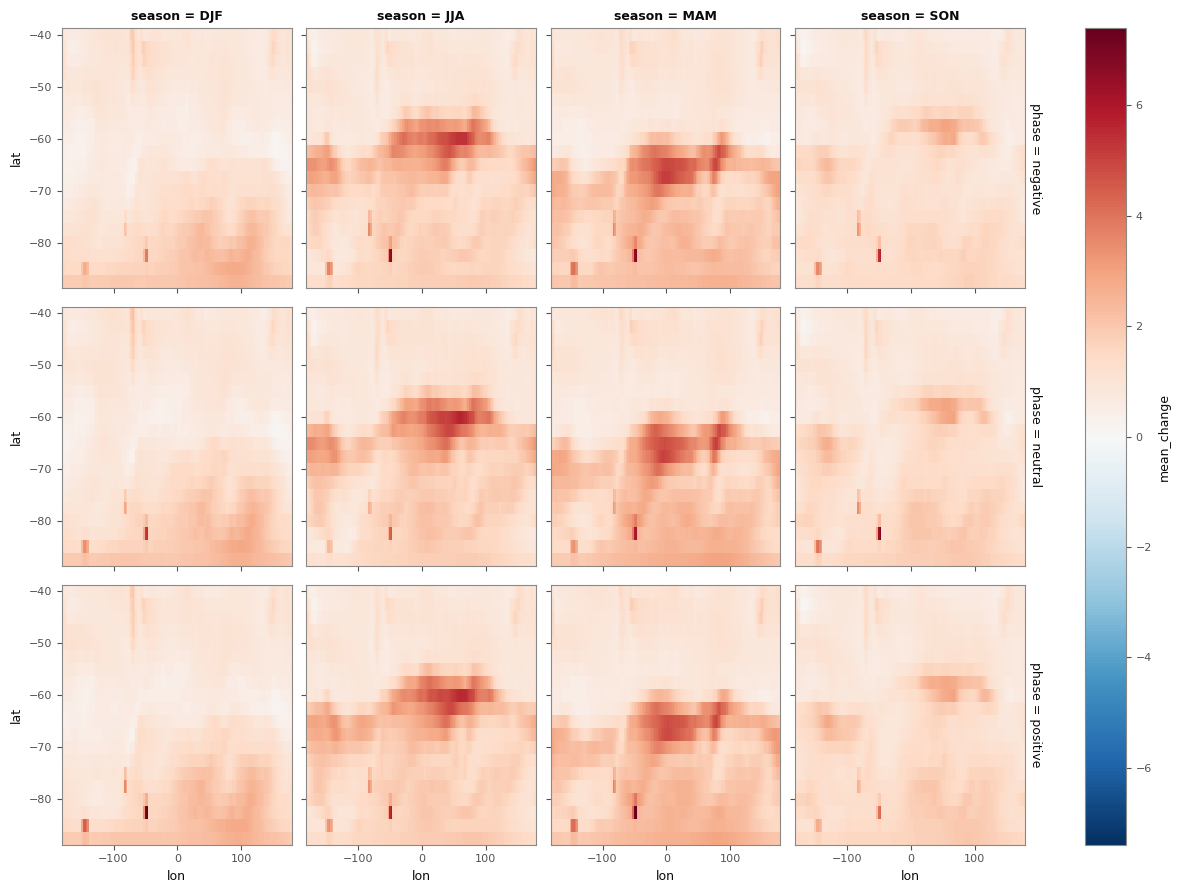

In [238]:
#(t): Quick look: DEMO_MODEL's change in the mean in each phase, DEMO_EXPERIMENT
sam_mean_bootstrap_ds['mean_change'].sel(model=DEMO_MODEL, experiment=DEMO_EXPERIMENT).plot(
    x='lon', y='lat', row='phase', col='season', cmap='RdBu_r', center=0);

## 2. Signal to Noise

**Signal.** The forced response of each experiment is its ensemble mean, smoothed with LOWESS (81 years); the signal is the experiment's minus hist-nat's:

$$
S(t) = F_{\mathrm{exp}}(t) - F_{\mathrm{nat}}(t), \qquad F(t) = \mathrm{LOWESS}\left(\tfrac{1}{M}\textstyle\sum_m x_{m,t}\right).
$$

(The ensemble means are smoothed as anomalies from their own whole-record mean, which is then added back; LOWESS commutes with adding a constant, so this changes nothing but the numerics.)

**Noise.** Each member's deviation from its own experiment's forced response, $x_{m,y} - F(y)$, pooled over members and a rolling $L$-year window, gives a standard deviation $\sigma(t)$ for each experiment; the noise pools the experiment's and hist-nat's:

$$
N(t) = \sqrt{\tfrac{1}{2}\left(\sigma^2_{\mathrm{exp}}(t) + \sigma^2_{\mathrm{nat}}(t)\right)}, \qquad \mathrm{S/N}(t) = \frac{S(t)}{N(t)}.
$$

$|\mathrm{S/N}| \ge 2$ counts as emerged. This asks a stricter question than the tests in section 1: whether the shift stands out from year-to-year noise, i.e. whether a single realisation, like the real world, would show it.

In [239]:
#(t): Each experiment's whole-record mean (no member dim, so a Dataset)
base_mean_ds = datatree.reduce_to_dataset(lesfmip_season_tree, lambda ds: ds.mean(dim=['year', 'member']))

In [240]:
#(t): Every member's anomaly from it (a tree)
base_mean_tree = datatree.dataset_to_tree(base_mean_ds, like=lesfmip_season_tree)
lesfmip_season_anom_tree = lesfmip_season_tree - base_mean_tree

In [241]:
#(t): Each experiment's ensemble-mean anomaly
lesfmip_mm_anom_ds = datatree.reduce_to_dataset(lesfmip_season_anom_tree, lambda ds: ds.mean(dim='member'))

In [242]:
#(t): smoothed with LOWESS (81 years): each experiment's forced response, as an anomaly
lesfmip_mm_signal_ds = qc.lowess_xarray(lesfmip_mm_anom_ds, core_dims='year').persist()
wait(lesfmip_mm_signal_ds)

DoneAndNotDoneFutures(done={<Future: finished, type: numpy.ndarray, key: ('transpose-4907516713e8c2f12a40035a7aaffe5b', 3, 3, 0, 0, 0, 4)>, <Future: finished, type: numpy.ndarray, key: ('transpose-4907516713e8c2f12a40035a7aaffe5b', 5, 4, 0, 0, 0, 0)>, <Future: finished, type: numpy.ndarray, key: ('transpose-4907516713e8c2f12a40035a7aaffe5b', 0, 2, 0, 0, 0, 4)>, <Future: finished, type: numpy.ndarray, key: ('transpose-4907516713e8c2f12a40035a7aaffe5b', 2, 1, 0, 0, 0, 2)>, <Future: finished, type: numpy.ndarray, key: ('transpose-4907516713e8c2f12a40035a7aaffe5b', 3, 4, 0, 0, 0, 0)>, <Future: finished, type: numpy.ndarray, key: ('transpose-4907516713e8c2f12a40035a7aaffe5b', 0, 4, 0, 0, 0, 3)>, <Future: finished, type: numpy.ndarray, key: ('transpose-4907516713e8c2f12a40035a7aaffe5b', 5, 3, 0, 0, 0, 1)>, <Future: finished, type: numpy.ndarray, key: ('transpose-4907516713e8c2f12a40035a7aaffe5b', 5, 0, 0, 0, 0, 3)>, <Future: finished, type: numpy.ndarray, key: ('transpose-4907516713e8c2f12a4

In [243]:
#(t): Each member's deviation from its experiment's forced response
lesfmip_mm_signal_tree = datatree.dataset_to_tree(lesfmip_mm_signal_ds, like=lesfmip_season_anom_tree)
lesfmip_detrend_tree = (lesfmip_season_anom_tree - lesfmip_mm_signal_tree).persist()
wait(lesfmip_detrend_tree)

DoneAndNotDoneFutures(done=set(), not_done=set())

In [244]:
#(t): Its standard deviation, every member's values pooled in the WINDOW years centred on each year
#(c): Persisted: the noise below is made from it, and it is saved too
lesfmip_experiment_noise_ds = datatree.reduce_to_dataset(lesfmip_detrend_tree, partial(qc.rolling_std, window=WINDOW))
lesfmip_experiment_noise_ds = lesfmip_experiment_noise_ds.persist()
wait(lesfmip_experiment_noise_ds)
lesfmip_experiment_noise_ds

<xarray.Dataset> Size: 453MB
Dimensions:     (model: 6, experiment: 5, lon: 144, year: 164, season: 4,
                 lat: 20)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Data variables:
    tas         (year, lat, lon, season, model, experiment) float64 453MB dask.array<chunksize=(164, 4, 144, 4, 1, 1), meta=np.ndarray>

In [245]:
%%time
#(t): The noise: each experiment's and hist-nat's pooled (slow)
lesfmip_noise_ds = np.sqrt(0.5 * (lesfmip_experiment_noise_ds.sel(experiment='hist-nat') ** 2
                                  + lesfmip_experiment_noise_ds ** 2)).compute()
lesfmip_noise_ds

CPU times: user 200 ms, sys: 300 ms, total: 499 ms
Wall time: 1.83 s


<xarray.Dataset> Size: 453MB
Dimensions:     (year: 164, lat: 20, lon: 144, season: 4, model: 6,
                 experiment: 5)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Data variables:
    tas         (year, lat, lon, season, model, experiment) float64 453MB 0.8...

In [246]:
%%time
#(t): Each experiment's forced response: the smoothed anomaly plus the whole-record mean
lesfmip_forced_ds = (lesfmip_mm_signal_ds + base_mean_ds).compute()
lesfmip_forced_ds

CPU times: user 228 ms, sys: 275 ms, total: 502 ms
Wall time: 3.44 s


<xarray.Dataset> Size: 453MB
Dimensions:     (model: 6, experiment: 5, lon: 144, year: 164, season: 4,
                 lat: 20)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Data variables:
    tas         (model, experiment, lon, year, season, lat) float64 453MB -27...

In [247]:
#(t): The signal: each experiment's forced response minus hist-nat's
lesfmip_signal_ds = lesfmip_forced_ds - lesfmip_forced_ds.sel(experiment='hist-nat')
lesfmip_signal_ds

<xarray.Dataset> Size: 453MB
Dimensions:     (model: 6, experiment: 5, lon: 144, year: 164, season: 4,
                 lat: 20)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Data variables:
    tas         (model, experiment, lon, year, season, lat) float64 453MB -0....

In [248]:
%%time
#(t): S/N
lesfmip_seasonal_sn_ds = (lesfmip_signal_ds / lesfmip_noise_ds).compute()
lesfmip_seasonal_sn_ds

CPU times: user 454 ms, sys: 44.5 ms, total: 498 ms
Wall time: 501 ms


<xarray.Dataset> Size: 453MB
Dimensions:     (model: 6, experiment: 5, lon: 144, year: 164, season: 4,
                 lat: 20)
Coordinates:
  * model       (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
  * season      (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
Data variables:
    tas         (model, experiment, lon, year, season, lat) float64 453MB -0....

In [249]:
#(t): Saved for notebooks plot_03 to plot_06
signal_path = RESULTS_DIR / 'signal.zarr'
lesfmip_signal_ds.to_zarr(signal_path, mode='w')
signal_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/signal.zarr')

In [250]:
#(t): Saved for notebooks plot_03 to plot_06
noise_path = RESULTS_DIR / 'noise.zarr'
lesfmip_noise_ds.to_zarr(noise_path, mode='w')
noise_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/noise.zarr')

In [251]:
#(t): Saved for notebooks plot_03 to plot_06
sn_path = RESULTS_DIR / 'sn.zarr'
lesfmip_seasonal_sn_ds.to_zarr(sn_path, mode='w')
sn_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/sn.zarr')

In [252]:
#(t): Saved for notebooks plot_03 to plot_06
forced_path = RESULTS_DIR / 'forced.zarr'
lesfmip_forced_ds.to_zarr(forced_path, mode='w')
forced_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/forced.zarr')

In [253]:
%%time
#(t): Saved for notebook plot_03; loaded from the cluster first, so it is written in one piece
experiment_noise_path = RESULTS_DIR / 'experiment_noise.zarr'
lesfmip_experiment_noise_ds.load().to_zarr(experiment_noise_path, mode='w')
experiment_noise_path

CPU times: user 3.87 s, sys: 1.09 s, total: 4.96 s
Wall time: 10.3 s


PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/experiment_noise.zarr')

The three parts at the demonstration point, picked out of the results, plotted plainly, then the method figure:

In [254]:
#(t): The demonstration point picked out of the forced responses, on (experiment, year)
point_forced_da = lesfmip_forced_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)
point_forced_da

<xarray.DataArray 'tas' (experiment: 5, year: 164)> Size: 7kB
-4.992 -4.99 -4.988 -4.985 -4.983 -4.981 ... -4.03 -4.02 -4.011 -4.002 -3.993
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0

In [255]:
#(t): of the noise
point_noise_da = lesfmip_noise_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)
point_noise_da

<xarray.DataArray 'tas' (year: 164, experiment: 5)> Size: 7kB
1.541 1.522 1.527 1.516 1.52 1.539 1.525 ... 1.467 1.391 1.563 1.527 1.561 1.47
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0

In [256]:
#(t): and of S/N
point_sn_da = lesfmip_seasonal_sn_ds[VARIABLE.name].sel(**DEMO_SEL).sel(**DEMO_LATLON)
point_sn_da

<xarray.DataArray 'tas' (experiment: 5, year: 164)> Size: 7kB
-0.0004351 -0.0004179 -0.0004021 -0.000386 ... 0.6813 0.6904 0.6935 0.6995
Coordinates:
    model       <U7 28B 'CanESM5'
  * experiment  (experiment) object 40B 'hist-GHG' 'hist-aer' ... 'historical'
    lon         float64 8B -180.0
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013
    season      <U3 12B 'DJF'
    lat         float64 8B -75.0

In [257]:
#(t): The ensemble means at the point: one per experiment, as a Dataset on (experiment, year, season)
demo_ensemble_mean_tree = demo_tree.mean('member')
demo_ensemble_mean_ds = datatree.tree_to_dataset(demo_ensemble_mean_tree, dims=['experiment'])

In [258]:
#(t): DEMO_EXPERIMENT's and hist-nat's, in the demonstration season
demo_ensemble_mean_da = demo_ensemble_mean_ds[VARIABLE.name].sel(experiment=[DEMO_EXPERIMENT, 'hist-nat'],
                                                            season=DEMO_POINT['season'])
demo_ensemble_mean_da

<xarray.DataArray 'tas' (year: 164, experiment: 2)> Size: 1kB
-4.928 -4.92 -4.961 -5.05 -4.906 -4.879 ... -4.945 -4.011 -4.883 -4.175 -4.586
Coordinates:
  * experiment  (experiment) object 16B 'historical' 'hist-nat'
    lat         float64 8B -75.0
    lon         float64 8B -180.0
    season      <U3 12B 'DJF'
  * year        (year) int64 1kB 1850 1851 1852 1853 ... 2010 2011 2012 2013

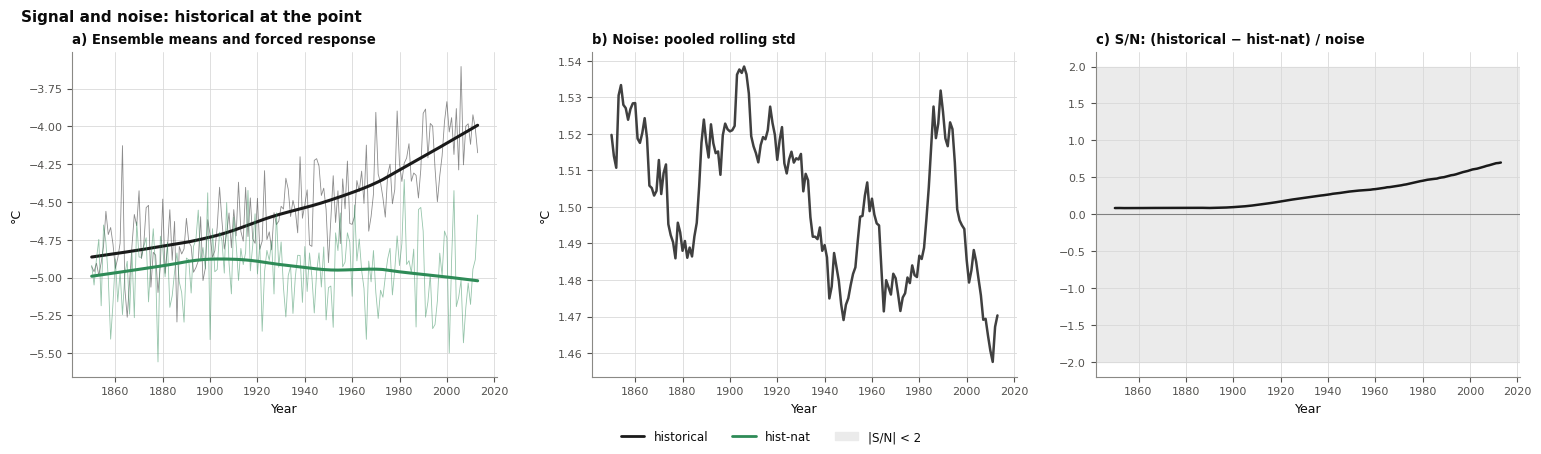

In [259]:
#(t): Signal, noise and their ratio at the point: a) each ensemble's mean (thin) and its smoothed forced response
#(t): (thick), the gap between the thick lines the signal; b) the noise, the pooled rolling standard deviation; c) S/N,
#(t): grey where |S/N| < 2 (not emerged)
sn_experiments = [DEMO_EXPERIMENT, 'hist-nat']
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=3, n_legends=1, panel_width=4.3, panel_height=2.8,
                                                  column_gap=0.75), layout='constrained')
axes = fig.add_gridspec(1, 3).subplots(sharex=True, squeeze=False)
for experiment in sn_experiments:
    charts.plot_lines(demo_ensemble_mean_da.sel(experiment=experiment), 'year', ax=axes[0, 0],
                      color=FORCING_COLORS[experiment], linewidth=0.6, alpha=0.5)
    charts.plot_lines(point_forced_da.sel(experiment=experiment), 'year', ax=axes[0, 0],
                      color=FORCING_COLORS[experiment], linewidth=2.2)
charts.plot_lines(point_noise_da.sel(experiment=DEMO_EXPERIMENT), 'year', ax=axes[0, 1], color='0.25', linewidth=1.8)
axes[0, 2].axhspan(-2, 2, color='0.92', zorder=0)
charts.plot_lines(point_sn_da.sel(experiment=DEMO_EXPERIMENT), 'year', ax=axes[0, 2],
                  color=FORCING_COLORS[DEMO_EXPERIMENT], linewidth=1.8)
axes[0, 2].axhline(0, color='0.5', lw=0.8)

axes[0, 0].set_title('a) Ensemble means and forced response', loc='left')
axes[0, 1].set_title('b) Noise: pooled rolling std', loc='left')
axes[0, 2].set_title(f'c) S/N: ({DEMO_EXPERIMENT} − hist-nat) / noise', loc='left')
for ax in axes[0, :2]:
    ax.set_ylabel(VARIABLE.units)
for ax in axes[0]:
    ax.set_xlabel('Year')
fig.legend(handles=charts.forcing_legend_handles(sn_experiments) + [Patch(color='0.92', label='|S/N| < 2')],
           loc='outside lower center', ncols=3, frameon=False)
fig.suptitle(f'Signal and noise: {DEMO_EXPERIMENT} at the point', x=0.01, ha='left');

**How `qc.rolling_std` gets the noise without a copy of the data for each window**, step by step at the demonstration point: DEMO_EXPERIMENT's members minus their forced response (`lesfmip_detrend_tree`), pooled over the `WINDOW` years centred on each year.

In [260]:
#(t): DEMO_EXPERIMENT's members minus their forced response at the point, on (member, year)
demo_deviation_da = lesfmip_detrend_tree[DEMO_MODEL][DEMO_EXPERIMENT][VARIABLE.name].sel(
    season=DEMO_POINT['season']).sel(**DEMO_LATLON).load()

In [261]:
#(t): Each year's three sums over the members: how many values, their sum, and the sum of their squares
# The variance of some values is the mean of their squares minus the square of their mean.
# Example: [1, 2, 3] has a mean of 2 and a mean square of (1 + 4 + 9) / 3 = 4.67, so its variance is 4.67 - 2² = 0.67.
# So a window's standard deviation needs only these three sums over its values, and each is a sum of the yearly sums.
demo_year_count_da = demo_deviation_da.count('member')
demo_year_sum_da = demo_deviation_da.sum('member')
demo_year_square_da = (demo_deviation_da ** 2).sum('member')

In [262]:
#(t): Each window's three sums, from running totals (qc._centred_sums): the total to the window's last year minus the
#(t): total before its first year
# Example: yearly sums [2, 3, 1, 4] have the running totals [0, 2, 5, 6, 10] (0 before the first year).
# The 3-year window centred on the third year runs from the second year to the fourth: 10 - 2 = 8, which is 3 + 1 + 4.
# At the ends the window is cut short: centred on the first year it is the first two years, 5 - 0 = 5.
# One running total serves every window, so no window's values are ever gathered.
demo_window_count_arr = qc._centred_sums(demo_year_count_da.values.astype(float), WINDOW)
demo_window_sum_arr = qc._centred_sums(demo_year_sum_da.values, WINDOW)
demo_window_square_arr = qc._centred_sums(demo_year_square_da.values, WINDOW)

In [263]:
#(t): Each window's standard deviation: the square root of its mean square minus its squared mean
demo_window_mean_arr = demo_window_sum_arr / demo_window_count_arr
demo_window_std_arr = np.sqrt(demo_window_square_arr / demo_window_count_arr - demo_window_mean_arr ** 2)

In [264]:
#(t): Check: the window centred on 1960 three ways: np.std of its values gathered (members and years pooled), the running
#(t): sums above, and qc.rolling_std
demo_rolling_std_da = qc.rolling_std(demo_deviation_da, window=WINDOW)
demo_1960_index = int(np.flatnonzero(demo_deviation_da['year'].values == 1960)[0])
(float(np.nanstd(demo_deviation_da.sel(year=slice(1960 - WINDOW // 2, 1960 + WINDOW // 2)).values)),
 float(demo_window_std_arr[demo_1960_index]), float(demo_rolling_std_da.sel(year=1960)))

(1.4856047999897166, 1.4856047999897157, 1.4856047999897157)

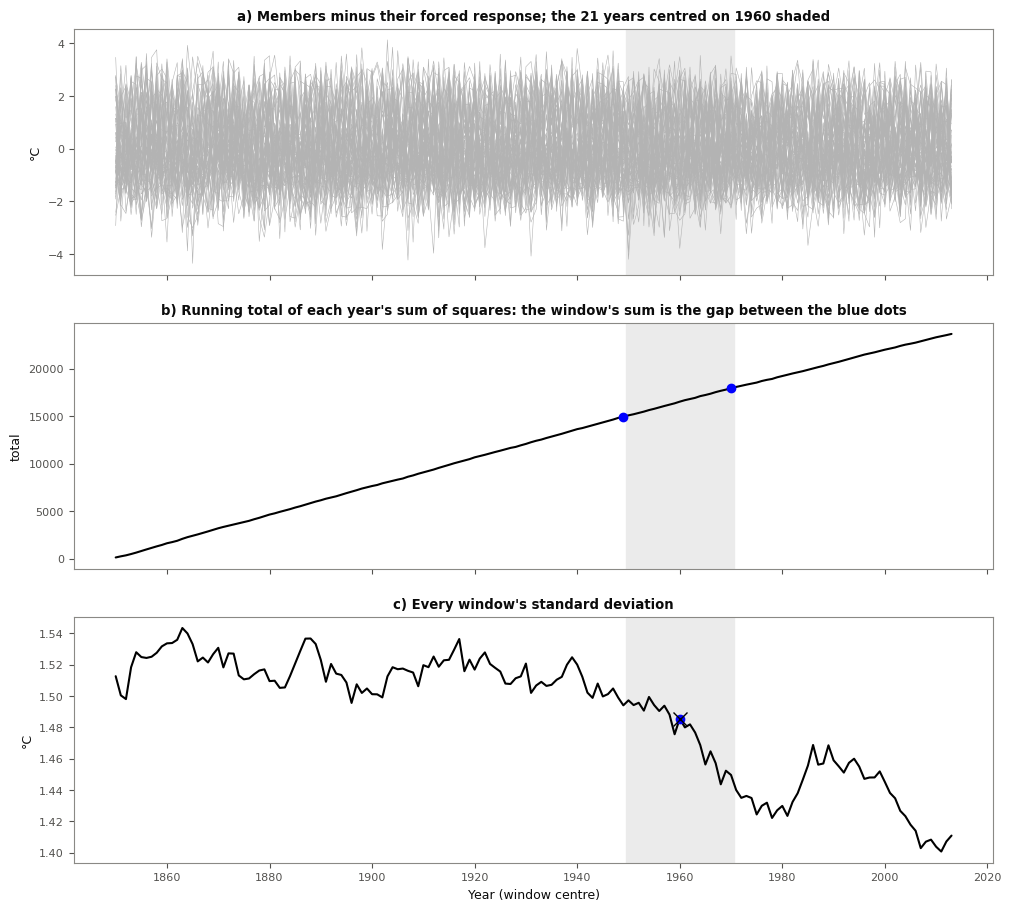

In [265]:
#(t): The running sums step by step, the window centred on 1960 shaded: a) the members minus their forced response; b) the
#(t): running total of each year's sum of squares, the window's sum the gap between the two blue dots; c) every window's
#(t): standard deviation, 1960's (blue) and np.std of its values gathered (black cross)
demo_years_arr = demo_deviation_da['year'].values
demo_first_year, demo_last_year = 1960 - WINDOW // 2, 1960 + WINDOW // 2
demo_square_total_arr = np.concatenate([[0], np.cumsum(demo_year_square_da.values)])
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 9), sharex=True, layout='constrained')
demo_deviation_da.plot.line(ax=ax1, x='year', hue='member', add_legend=False, color='0.7', lw=0.4)
ax1.set(title=f'a) Members minus their forced response; the {WINDOW} years centred on 1960 shaded', xlabel='',
        ylabel=VARIABLE.units)
ax2.plot(demo_years_arr, demo_square_total_arr[1:], color='k')
ax2.plot([demo_first_year - 1, demo_last_year],
         [demo_square_total_arr[demo_first_year - demo_years_arr[0]], demo_square_total_arr[demo_last_year - demo_years_arr[0] + 1]],
         'o', color='blue')
ax2.set(title="b) Running total of each year's sum of squares: the window's sum is the gap between the blue dots",
        xlabel='', ylabel='total')
ax3.plot(demo_years_arr, demo_window_std_arr, color='k')
ax3.plot(1960, demo_window_std_arr[demo_1960_index], 'o', color='blue')
ax3.plot(1960, np.nanstd(demo_deviation_da.sel(year=slice(demo_first_year, demo_last_year)).values), 'x', color='k', ms=10)
ax3.set(title="c) Every window's standard deviation", xlabel='Year (window centre)', ylabel=VARIABLE.units)
for ax in (ax1, ax2, ax3):
    ax.axvspan(demo_first_year - 0.5, demo_last_year + 0.5, color='0.92', zorder=0);

## 3. Additivity: Each Forcing's Change from Its Own Baseline

Single-forcing experiments contain *only* their forcing, so each one's response is best measured from its own pre-industrial baseline (1850–1900), not from hist-nat's full record. Measuring everything from hist-nat's full-record mean subtracts hist-nat's average volcanic cooling from every single forcing, so a sum of four forcings would subtract it four times while historical subtracts it once.

The **residual**, historical − (nat + GHG + aer + O3), holds everything the parts leave out: land use (hist-lu, which should be very small over Antarctica), any other forcing, and non-additive interaction between forcings. Fractions of historical are only given where |historical| ≥ 0.25 °C; elsewhere they blow up.

$$
\Delta_e = \bar{x}^{\,e}_{\text{final } L \text{ years}} - \bar{x}^{\,e}_{1850\text{–}1900},
\qquad
\text{residual} = \Delta_{\mathrm{historical}} - \left(\Delta_{\mathrm{nat}} + \Delta_{\mathrm{GHG}} + \Delta_{\mathrm{aer}} + \Delta_{\mathrm{O_3}}\right).
$$

In [266]:
#(t): Every experiment's 1850-1900 baseline
lesfmip_baseline_tree = lesfmip_season_tree.sel(year=slice(1850, 1900))

In [267]:
%%time
#(t): Its ensemble mean over those years
baseline_mean_ds = datatree.reduce_to_dataset(lesfmip_baseline_tree, lambda ds: ds.mean(['year', 'member'])).compute()

CPU times: user 83.4 ms, sys: 7.65 ms, total: 91 ms
Wall time: 786 ms


In [ ]:
#(t): Each experiment's change from its own baseline: the final WINDOW years (section 1) minus 1850-1900, ensemble means
own_changes_ds = final_mean_ds - baseline_mean_ds
own_changes_da = own_changes_ds[VARIABLE.name].rename('own_change')
own_changes_da

In [269]:
#(t): Saved for notebooks plot_03 to plot_06
own_changes_path = RESULTS_DIR / 'own_changes.zarr'
own_changes_da.to_dataset(name='own_change').to_zarr(own_changes_path, mode='w')
own_changes_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/own_changes.zarr')

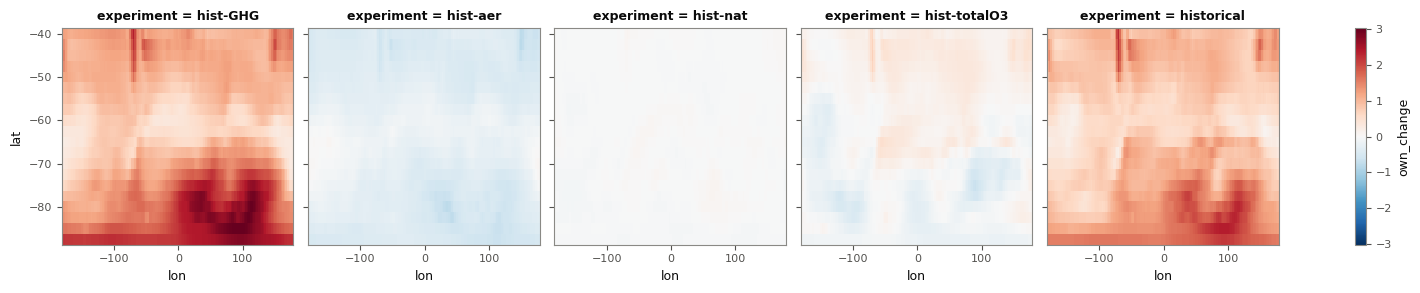

In [270]:
#(t): Quick look: DEMO_MODEL's change from its own 1850-1900 baseline in one season
own_changes_da.sel(**DEMO_SEL).plot(x='lon', y='lat', col='experiment', cmap='RdBu_r', center=0);

## 4. Zonal Means of the Mean: the Change at Each Latitude

Bracegirdle et al. (2024, *npj Clim. Atmos. Sci.* 7, 276) show the change in the low extremes, the mean, the high extremes and the width between them against latitude, averaged round the pole, with the sea-ice edge marked. Notebook plot_03 (section 7) draws the same, for every model on its own. This section tests the zonal mean of the mean with the hist-nat bootstrap of section 1. A trial draws the same 10 hist-nat members at every grid point, so its changes (its mean minus hist-nat's) averaged over longitude are one draw of what natural variability alone does to the zonal mean. A mean is linear, so the change in the zonal mean is the zonal mean of the change at each point: the test is of exactly the plotted line.

The zonal mean of the width is tested the same way in notebook calc_02a (section 5); its test is opened here for the figure at the end.

In [ ]:
#(t): The zonal-mean change in the mean (section 1)
zonal_mean_change_da = zonal.zonal_mean(mean_bootstrap_change_da)

In [ ]:
#(t): The zonal mean of every bootstrap trial's change (section 1): the zonal-mean null
zonal_null_mean_da = zonal.zonal_mean(null_mean_da)

In [286]:
%%time
#(t): The two-sided p-value of every experiment's zonal-mean change against its model's trials
zonal_mean_pvalue_da = sig.pvalue_two_sided(zonal_null_mean_da, zonal_mean_change_da).compute()

CPU times: user 22.5 ms, sys: 2.34 ms, total: 24.8 ms
Wall time: 251 ms


In [287]:
#(t): The zonal mean test in one Dataset, laid out as notebook plot_03 opens it
zonal_mean_ds = xr.Dataset({'mean_change': zonal_mean_change_da, 'pvalue': zonal_mean_pvalue_da})
zonal_mean_ds

<xarray.Dataset> Size: 23kB
Dimensions:      (model: 6, experiment: 4, season: 4, lat: 20)
Coordinates:
  * model        (model) object 48B 'CanESM5' 'GISS-E2-1-G' ... 'NorESM2-LM'
  * experiment   (experiment) object 32B 'hist-GHG' 'hist-aer' ... 'historical'
  * season       (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
  * lat          (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
Data variables:
    mean_change  (lat, season, model, experiment) float32 8kB 2.494 ... 0.2899
    pvalue       (lat, season, model, experiment) float64 15kB 0.001998 ... 0...

In [294]:
#(t): Saved for notebooks plot_03 to plot_06
zonal_mean_test_path = RESULTS_DIR / 'zonal_mean_test.zarr'
zonal_mean_ds.to_zarr(zonal_mean_test_path, mode='w')
zonal_mean_test_path

PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full/zonal_mean_test.zarr')

In [ ]:
#(t): The zonal width test notebook calc_02a saved (its section 5)
zonal_width_test_path = RESULTS_DIR / 'zonal_width_test.zarr'
zonal_width_test_path

In [ ]:
zonal_width_ds = xr.open_zarr(zonal_width_test_path).load()

For the demonstration model and season: the zonal-mean change in the mean and in the width for each experiment, with dots where it is significant. The grey band in the width panel is the central 95% of the hist-nat trials, the changes natural variability gives on its own; a line outside it is significant.

In [296]:
#(t): The zonal tests together, for DEMO_MODEL in its season, on (experiment, lat)
zonal_demo_ds = xr.merge([zonal_mean_ds.rename(pvalue='mean_pvalue'), zonal_width_ds], join='outer').sel(
    model=DEMO_MODEL, season=DEMO_POINT['season'])
zonal_demo_ds

<xarray.Dataset> Size: 3kB
Dimensions:         (experiment: 4, lat: 20)
Coordinates:
    model           <U7 28B 'CanESM5'
  * experiment      (experiment) object 32B 'hist-GHG' ... 'historical'
    season          <U3 12B 'DJF'
  * lat             (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
Data variables:
    mean_change     (lat, experiment) float32 320B 2.494 -0.4453 ... 0.248 1.017
    mean_pvalue     (lat, experiment) float64 640B 0.001998 ... 0.001998
    width_change    (lat, experiment) float64 640B -0.1202 -0.09157 ... -0.06538
    width_pvalue    (lat, experiment) float64 640B 0.6394 0.7772 ... 0.06593
    hist_nat_width  (lat) float64 160B 3.305 3.826 4.043 ... 1.424 1.517 1.566
    null_lower      (lat) float64 160B -0.3022 -0.2638 -0.23 ... -0.0679 -0.0673
    null_upper      (lat) float64 160B 0.2413 0.1732 0.1327 ... 0.03131 0.03007

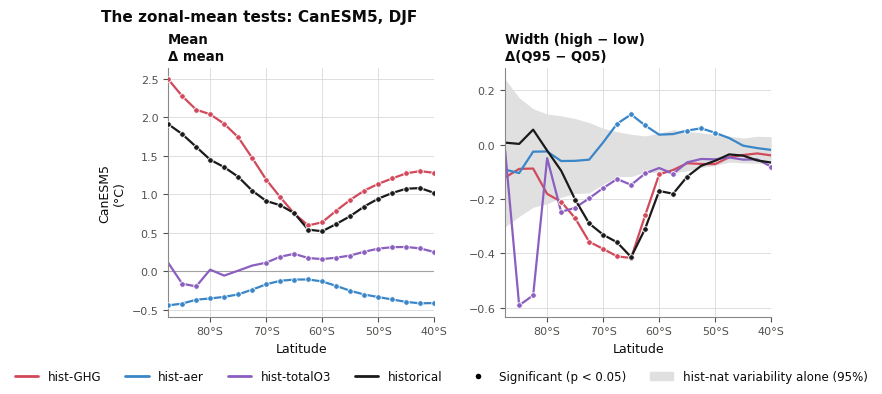

In [297]:
#(t): The zonal-mean tests: the change in the mean and in the width at each latitude, one line per experiment, a dot
#(t): where it is significant (p < ALPHA); grey, the central 95% of hist-nat's own width changes
zonal_demo_experiments = [e for e in FORCING_COLORS if e in zonal_demo_ds['experiment'].values]
fig = plt.figure(figsize=charts.chart_figure_size(n_rows=1, n_cols=2, n_legends=1), layout='constrained')
axes = fig.add_gridspec(1, 2).subplots(sharex=True, squeeze=False)
for ax in axes[0]:
    ax.axhline(0, color='0.64', linewidth=0.8, zorder=1)
charts.plot_band(zonal_demo_ds['null_lower'], zonal_demo_ds['null_upper'], 'lat', ax=axes[0, 1], color=zp.NULL_COLOR)
for experiment in zonal_demo_experiments:
    experiment_zonal_ds = zonal_demo_ds.sel(experiment=experiment)
    for ax, change, pvalue in zip(axes[0], ['mean_change', 'width_change'], ['mean_pvalue', 'width_pvalue']):
        charts.plot_lines(experiment_zonal_ds[change], 'lat', ax=ax, color=FORCING_COLORS[experiment], linewidth=1.6)
        charts.plot_significant_dots(experiment_zonal_ds[change], experiment_zonal_ds[pvalue] < ALPHA, 'lat', ax=ax,
                                     color=FORCING_COLORS[experiment])
axes[0, 0].set_title('Mean\nΔ mean', loc='left')
axes[0, 1].set_title('Width (high − low)\nΔ(Q95 − Q05)', loc='left')
axes[0, 0].set_ylabel(f'{DEMO_MODEL}\n({VARIABLE.units})')
for ax in axes[0]:
    ax.set_xlabel('Latitude')
axes[0, 0].xaxis.set_major_formatter(zp.latitude_label)
axes[0, 0].set_xlim(float(zonal_demo_ds['lat'].min()), float(zonal_demo_ds['lat'].max()))
fig.legend(handles=charts.forcing_legend_handles(zonal_demo_experiments) + [
plot_constants.significant_handle,
Patch(color=zp.NULL_COLOR, label='hist-nat variability alone (95%)')],
loc='outside lower center', ncols=len(zonal_demo_experiments) + 2, frameon=False)
fig.suptitle(f"The zonal-mean tests: {DEMO_MODEL}, {DEMO_POINT['season']}", x=0.01, ha='left');

## Saved Results

Everything this notebook saved, in `RESULTS_DIR`:

In [437]:
#(t): Everything this notebook saved in RESULTS_DIR
RESULTS_DIR, sorted(path.name for path in RESULTS_DIR.glob('*.zarr'))

(PosixPath('/work/scratch-pw4/aborow/ExtAnt/results/tas/full'),
 ['anomaly_ranks.zarr',
  'demo_anomaly_ranks.zarr',
  'demo_detrended_ranks.zarr',
  'demo_plume.zarr',
  'demo_statistics.zarr',
  'demo_tests.zarr',
  'detections.zarr',
  'detrended_ranks.zarr',
  'era5_kurtosis.zarr',
  'era5_lower_tail.zarr',
  'era5_mean.zarr',
  'era5_point.zarr',
  'era5_regional.zarr',
  'era5_regional_trend.zarr',
  'era5_skewness.zarr',
  'era5_std.zarr',
  'era5_trend.zarr',
  'era5_upper_tail.zarr',
  'era5_width.zarr',
  'eval_map_table.zarr',
  'eval_table.zarr',
  'experiment_noise.zarr',
  'final_mean.zarr',
  'final_quantiles.zarr',
  'first_look.zarr',
  'forced.zarr',
  'hist_nat_final_quantiles.zarr',
  'histnat_point.zarr',
  'historical_kurtosis.zarr',
  'historical_lower_tail.zarr',
  'historical_mean.zarr',
  'historical_point.zarr',
  'historical_skewness.zarr',
  'historical_std.zarr',
  'historical_trend.zarr',
  'historical_upper_tail.zarr',
  'historical_width.zarr',
  'mean_